# Reaction time across conditions
Investigating the reaction time across visual, auditory and audiovisual trials as well as in conflicted and with object 215

<u>Calculation of reaction time (RT)</u>: 
$$ 
RT = t_{response} - t_{stimulus onset} 
$$

In [2]:
import datajoint as dj
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from multimodal_analysis.db import get_schema_modules

exp, stim, beh, inter, rec, mice = get_schema_modules()

from multimodal_analysis.config import (
    add_behavior_sessions,
    create_analysis_key,
    get_animal_ids,
    get_behavior_sessions,
    get_task_types,
    plot_behavior_task_types,
    remove_behavior_sessions,
)

Please enter DataJoint username:  eflab
Please enter DataJoint password:  ········


[2026-11-06 08:50:27,663][INFO]: Connecting eflab@database.eflab.org:3306
[2026-11-06 08:50:27,689][INFO]: Connected eflab@database.eflab.org:3306


# Data overview

In [85]:
get_animal_ids()

['288', '299', '324', '326', '328', '410']

In [563]:
# Get available behavioral task types from beh_sessions.json.
# Parameters: animal_id (str | None)
get_task_types(animal_id=None)

['audiovisual',
 'audiovisual_conflicted',
 'audiovisual_diff',
 'audiovisual_no_stim',
 'audiovisual_obj215',
 'visual']

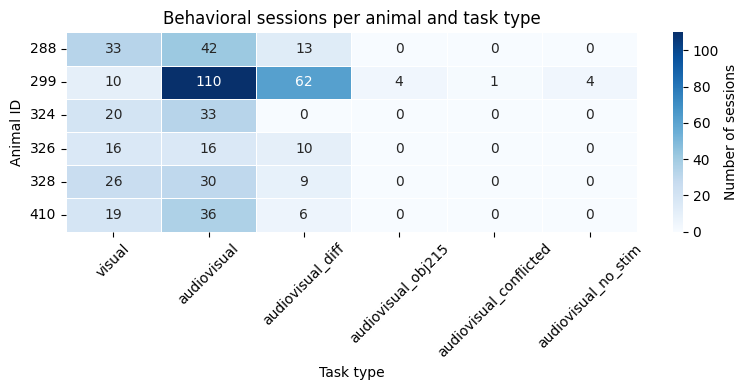

In [111]:
# Plot behavioral task types across animals.
# Parameter:
# show_counts (bool): If True, display the number of sessions per task type.
task_type_across_animals = plot_behavior_task_types(show_counts=True)

# Animal-level analysis of RT in multimodal trials

In [5]:
# Define the animal and behavioral task for the analysis
# Set animal_id to None to include all animals
# Available task types: "visual", "audiovisual", "audiovisual_diff", "audiovisual_no_stim", 
# "audiovisual_obj215", "audiovisual_conflicted"
animal_id = 444
task_type = "audiovisual_conflicted"

# Define the difficulty levels and sessions to exclude.
difficulties = [12]
excluded_sessions = []

In [573]:
# Get the behavioral sessions available for the selected animal and task.
sessions_idx = get_behavior_sessions(animal_id=animal_id, task_type=task_type)
print("sessions_idx: \n", sessions_idx)

# Define the first session to include in the analysis.
from_session = get_behavior_sessions(animal_id=animal_id, task_type=task_type)[0]
print("\nfrom_session:", from_session)

# Define the last session to include in the analysis.
to_session = get_behavior_sessions(animal_id=animal_id, task_type=task_type)[-1]
print("to_session:", to_session)

# Calculate the total number of sessions included in the analysis.
total_sessions = len(sessions_idx[:])
print("total_sessions:", total_sessions)

sessions_idx: 
 [681]

from_session: 681
to_session: 681
total_sessions: 1


In [13]:
rt_sessions = []

for session in sessions_idx:
    key = {"animal_id": animal_id, "session": session}

    # unimodal-visual trials
    vis_trials = (
        (
            stim.StimCondition.Trial
            * (stim.Panda.Object).proj("obj_mag")
            * exp.Trial.StateOnset
            * (stim.Tones).proj("tone_volume")
            & "tone_volume = 0"
            & key
            & 'state IN ("Reward", "Punish")'
        )
        .fetch(format="frame")
        .reset_index()
    )

    vis_trials["obj_mag"] = pd.to_numeric(vis_trials["obj_mag"], errors="coerce")
    vis_trials = vis_trials.loc[vis_trials["obj_mag"] > 0].copy()

    # unimodal-auditory trials
    auditory_trials = (
        (
            stim.StimCondition.Trial
            * (stim.Panda.Object).proj("obj_mag")
            * exp.Trial.StateOnset
            * (stim.Tones).proj("tone_volume")
            & "tone_volume > 0"
            & key
            & 'state IN ("Reward", "Punish")'
        )
        .fetch(format="frame")
        .reset_index()
    )

    auditory_trials["obj_mag"] = pd.to_numeric(
        auditory_trials["obj_mag"], errors="coerce"
    )
    auditory_trials = auditory_trials.loc[auditory_trials["obj_mag"] == 0].copy()

    # multimodal trials
    multi_trials = (
        (
            stim.StimCondition.Trial
            * (stim.Panda.Object).proj("obj_mag")
            * exp.Trial.StateOnset
            * (stim.Tones).proj("tone_volume")
            & "tone_volume > 0"
            & key
            & 'state IN ("Reward", "Punish")'
        )
        .fetch(format="frame")
        .reset_index()
    )

    multi_trials["obj_mag"] = pd.to_numeric(multi_trials["obj_mag"], errors="coerce")
    multi_trials = multi_trials.loc[multi_trials["obj_mag"] > 0].copy()

    # Calculate reaction time and label each condition
    for df, modality in [
        (vis_trials, "Visual"),
        (auditory_trials, "Auditory"),
        (multi_trials, "Audiovisual"),
    ]:
        df = df.copy()

        df = df.rename(
            columns={
                "start_time": "stim_onset",
                "time": "response_onset",
            }
        )

        df["rt"] = (df["response_onset"] - df["stim_onset"]) / 1000

        df["modality"] = modality

        rt_sessions.append(df)

    rt_df = pd.concat(rt_sessions, ignore_index=True)
    
    # Keep valid positive reaction times
    rt_df = rt_df.dropna(subset=["rt"])
    rt_df = rt_df.loc[rt_df["rt"] > 0].copy()

In [6]:
# Find the conditions present in each session
conditions_per_session = (
    rt_df.groupby("session")["modality"]
    .unique()
)

# Keep sessions containing all three conditions
required_conditions = {"Visual", "Auditory", "Audiovisual"}

valid_sessions = conditions_per_session[
    conditions_per_session.apply(
        lambda conditions: required_conditions.issubset(set(conditions)) 
    )
].index

# Filter the trial-level DataFrame
rt_df = rt_df[rt_df["session"].isin(valid_sessions)].copy()

In [7]:
session_rt = (
    rt_df
    .groupby(["session", "modality"])["rt"]
    .agg(
        median_rt="median",
        mean_rt="mean",
        std_rt="std",
        n_trials="count",
    )
    .reset_index()
)

In [8]:
session_rt.head(10)

,session,modality,median_rt,mean_rt,std_rt,n_trials
0,107,Audiovisual,0.7430,0.748206,0.097976,165
1,107,Auditory,1.3600,2.051600,1.544839,15
2,107,Visual,0.6910,0.691912,0.086214,34
3,111,Audiovisual,0.8145,0.810137,0.121374,204
4,111,Auditory,4.5060,4.418333,2.816599,9
5,111,Visual,0.7300,0.743353,0.075907,17
6,113,Audiovisual,0.8190,0.830261,0.149189,203
7,113,Auditory,1.1435,1.544750,0.687909,12
8,113,Visual,0.9220,0.899926,0.137134,27
9,117,Audiovisual,0.7700,0.789579,0.118824,159


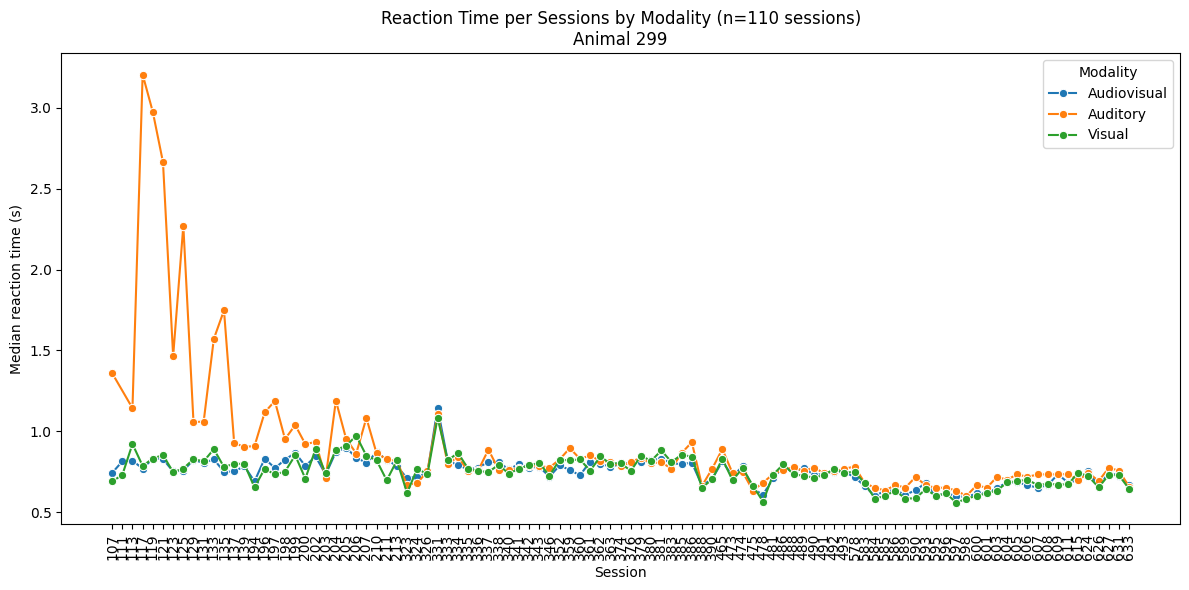

In [43]:
session_order = sorted(session_rt["session"].unique())

session_positions = {
    session: i for i, session in enumerate(session_order)
}

session_rt["session_position"] = session_rt["session"].map(session_positions)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=session_rt,
    x="session_position",
    y="median_rt",
    hue="modality",
    marker="o",
)

plt.xlabel("Session")
plt.ylabel("Median reaction time (s)")
plt.title(f"Reaction Time per Sessions by Modality (n={total_sessions} sessions)\nAnimal {animal_id}")

plt.xticks(
    ticks=range(len(session_order)),
    labels=session_order,
    rotation=90,
)

plt.legend(title="Modality")
plt.tight_layout()
plt.show()

# MultiAnimal-level analysis of RT in multimodal trials

## Reaction Interval between <b> stimulus onset & response state</b>

In [114]:
animals = get_animal_ids()
# animals = [326]
animals

['288', '299', '324', '326', '328', '410']

### Reaction Interval between <b> stimulus onset & response state</b> - <u>Audiovisual trials</u>

In [136]:
rt_sessions = []

for animal in animals:
    task_type = "audiovisual"
    excluded_sessions = []

    # Get the behavioral sessions available for the selected animal and task.
    sessions_idx = get_behavior_sessions(animal_id=animal, task_type=task_type)

    # Exclude sessions if necessary.
    sessions_idx = [
        session for session in sessions_idx if session not in excluded_sessions
    ]

    for session in sessions_idx:
        key = {"animal_id": animal, "session": session}

        # unimodal-visual trials
        vis_trials = (
            (
                stim.StimCondition.Trial
                * (stim.Panda.Object).proj("obj_mag")
                * exp.Trial.StateOnset
                * (stim.Tones).proj("tone_volume")
                & "tone_volume = 0"
                & key
                & 'state IN ("Reward", "Punish")'
            )
            .fetch(format="frame")
            .reset_index()
        )

        vis_trials["obj_mag"] = pd.to_numeric(vis_trials["obj_mag"], errors="coerce")
        vis_trials = vis_trials.loc[vis_trials["obj_mag"] > 0].copy()

        # unimodal-auditory trials
        auditory_trials = (
            (
                stim.StimCondition.Trial
                * (stim.Panda.Object).proj("obj_mag")
                * exp.Trial.StateOnset
                * (stim.Tones).proj("tone_volume")
                & "tone_volume > 0"
                & key
                & 'state IN ("Reward", "Punish")'
            )
            .fetch(format="frame")
            .reset_index()
        )

        auditory_trials["obj_mag"] = pd.to_numeric(
            auditory_trials["obj_mag"], errors="coerce"
        )
        auditory_trials = auditory_trials.loc[auditory_trials["obj_mag"] == 0].copy()

        # multimodal trials
        multi_trials = (
            (
                stim.StimCondition.Trial
                * (stim.Panda.Object).proj("obj_mag")
                * exp.Trial.StateOnset
                * (stim.Tones).proj("tone_volume")
                & "tone_volume > 0"
                & key
                & 'state IN ("Reward", "Punish")'
            )
            .fetch(format="frame")
            .reset_index()
        )

        multi_trials["obj_mag"] = pd.to_numeric(
            multi_trials["obj_mag"], errors="coerce"
        )
        multi_trials = multi_trials.loc[multi_trials["obj_mag"] > 0].copy()

        # Apply session inclusion criteria.
        # 1. At least 100 audiovisual trials.
        # 2. At least 50 unimodal trials in total (visual + auditory).
        # 3. All three modalities must be present.

        # Count valid trials in each modality.
        n_visual = len(vis_trials)
        n_auditory = len(auditory_trials)
        n_audiovisual = len(multi_trials)
        
        if (
            n_audiovisual < 100
            or (n_visual + n_auditory) < 50
            or n_visual == 0
            or n_auditory == 0
        ):
            continue
        

        # Calculate reaction time and label each condition
        for df, modality in [
            (vis_trials, "Visual"),
            (auditory_trials, "Auditory"),
            (multi_trials, "Audiovisual"),
        ]:
            df = df.copy()

            df = df.rename(
                columns={
                    "start_time": "stim_onset",
                    "time": "response_onset",
                }
            )

            df["rt"] = (df["response_onset"] - df["stim_onset"]) / 1000

            df["modality"] = modality            

            rt_sessions.append(df)

rt_df = pd.concat(rt_sessions, ignore_index=True)

# Remove rows with missing reaction times or modalities.
session_rt = rt_df.dropna(subset=["rt", "modality"]).copy()

# Keep reaction times between 0 and 2.0
session_rt_filtered = session_rt.loc[(session_rt["rt"] > 0) & (session_rt["rt"] <= 2.0)].copy()

# Calculate the median RT for each animal, session, and modality.
session_rt = (
    session_rt_filtered.groupby(["animal_id", "session", "modality"])["rt"]
    .agg(
        median_rt="median",
        n_trials="count",
    )
    .reset_index()
)

session_rt = session_rt[session_rt['n_trials'] > 50]

session_rt

,animal_id,session,modality,median_rt,n_trials
0,288,184,Audiovisual,0.6860,226
2,288,184,Visual,0.6970,55
3,288,186,Audiovisual,0.6680,233
5,288,186,Visual,0.6785,56
6,299,336,Audiovisual,0.7750,117
...,...,...,...,...,...
283,410,194,Auditory,0.7510,69
284,410,194,Visual,0.6550,61
285,410,196,Audiovisual,0.6390,193
286,410,196,Auditory,0.7415,66


In [137]:
x = np.unique(session_rt[session_rt['modality'] == 'Visual']['n_trials'])
x

array([ 51,  52,  54,  55,  56,  57,  58,  60,  61,  62,  63,  64,  65,
        66,  67,  70,  71,  72,  73,  74,  78,  89,  97, 102, 125, 143,
       156])

<u>Procedure:</u> individual trials RTs → median RT per animal/session/modality → mean ± SD across animals.

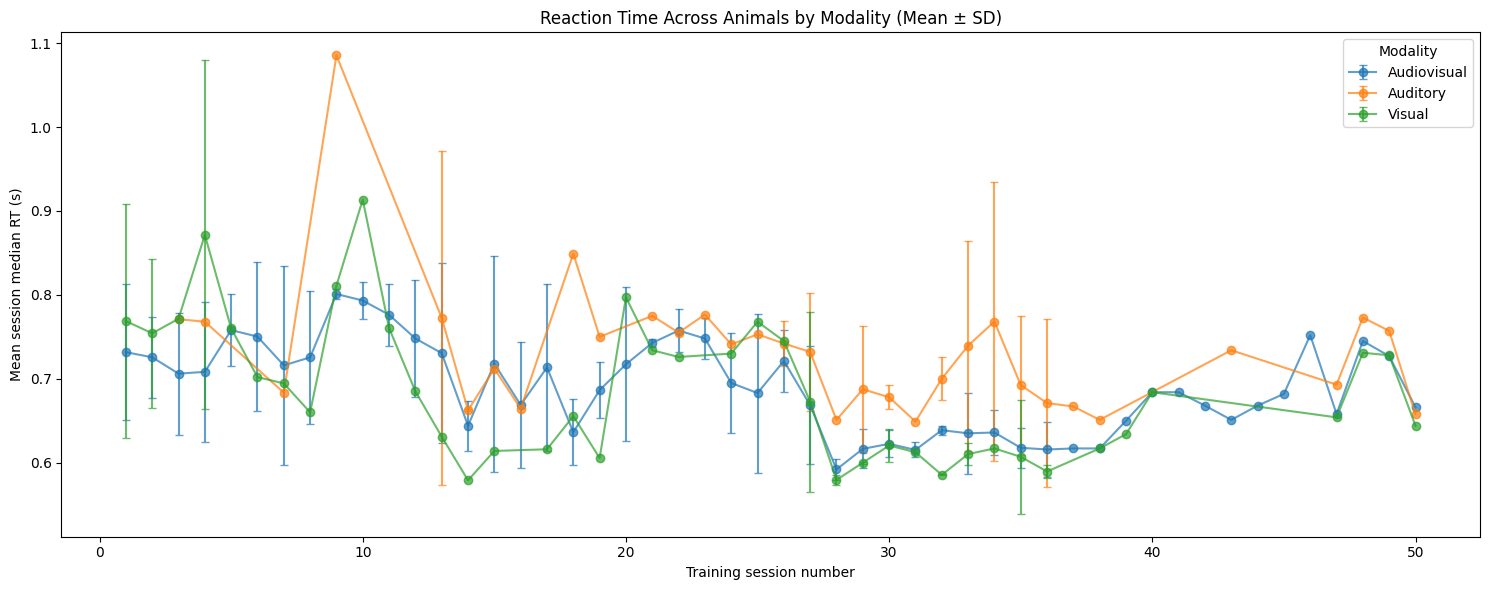

In [138]:
# Assign consecutive session positions within each animal
session_rt["session_position"] = session_rt.groupby("animal_id")["session"].rank(
    method="dense"
)

# session_rt = session_rt[session_rt['session_position'] > 43.0]

# Calculate mean and SD across animals at each position and modality
across_animals = (
    session_rt.groupby(["session_position", "modality"])["median_rt"]
    .agg(
        mean_rt="mean",
        sd_rt="std",
        n_animals="count",
    )
    .reset_index()
)

# Plot mean ± SD
plt.figure(figsize=(15, 6))

for modality, data in across_animals.groupby("modality"):
    data = data.sort_values("session_position")

    plt.errorbar(
        data["session_position"],
        data["mean_rt"],
        yerr=data["sd_rt"],
        marker="o",
        capsize=3,
        linewidth=1.5,
        label=modality,
        alpha=0.7,
    )

plt.xlabel("Training session number")
plt.ylabel("Mean session median RT (s)")
plt.title("Reaction Time Across Animals by Modality (Mean ± SD)")
plt.legend(title="Modality")

plt.tight_layout()
plt.show()

ValueError: Could not interpret value `session_position` for `x`. An entry with this name does not appear in `data`.

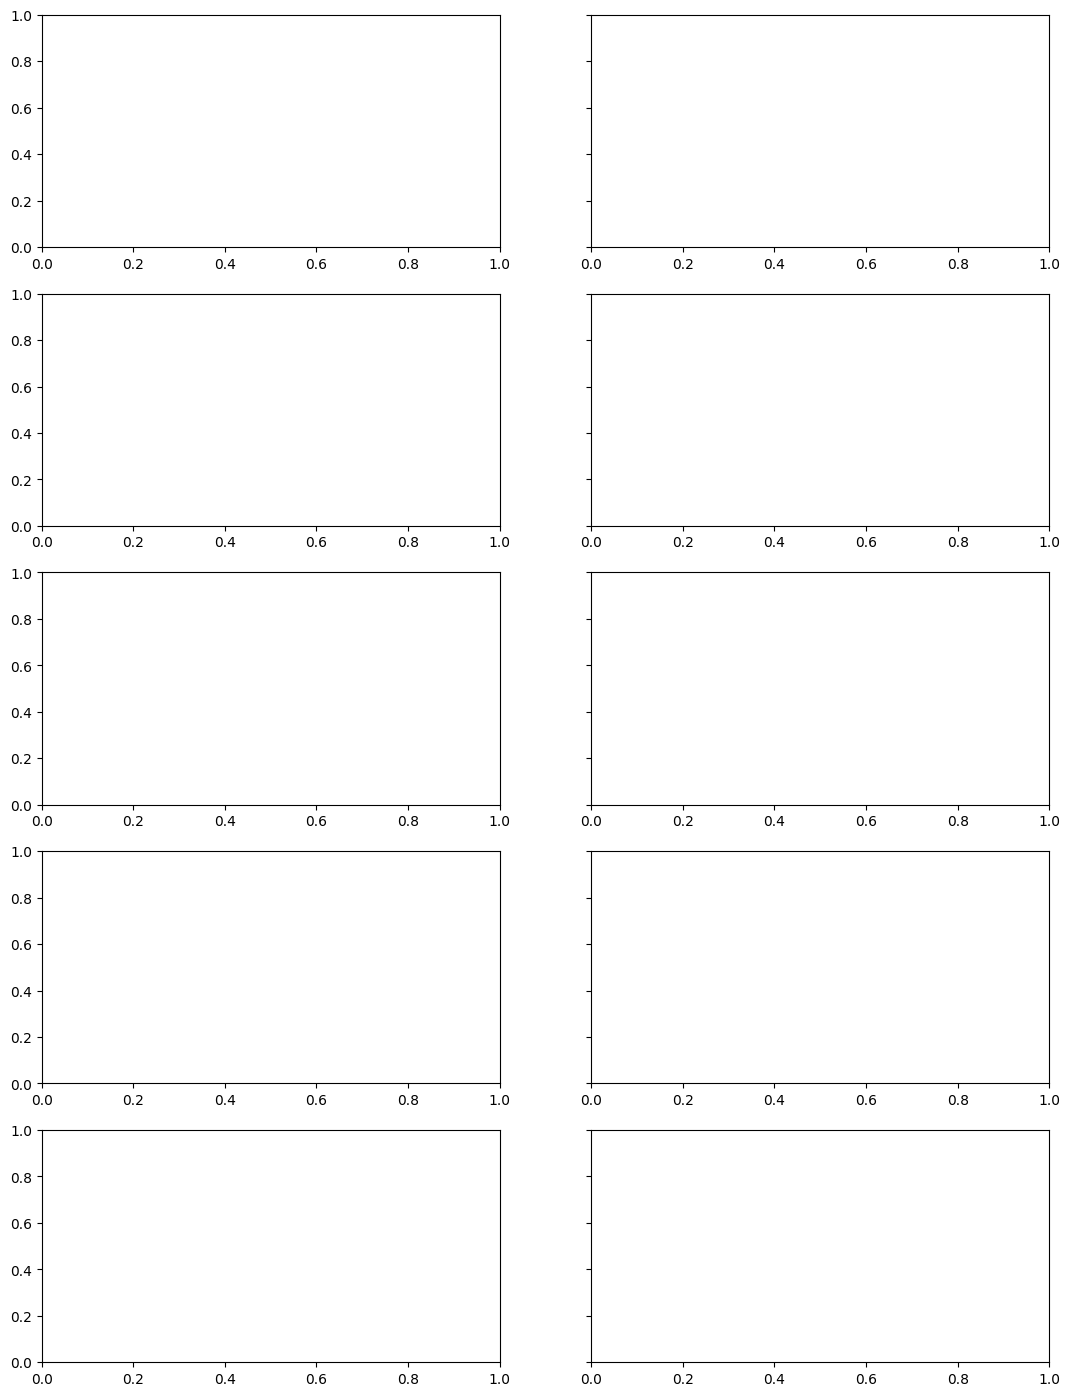

In [139]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Keep the three relevant modalities
plot_data = session_rt[
    session_rt["modality"].isin(["Visual"])
].copy()

# Create session position separately for each animal
session_positions = (
    plot_data[["animal_id", "session"]]
    .drop_duplicates()
    .sort_values(["animal_id", "session"])
)

session_positions["session_position"] = (
    session_positions.groupby("animal_id").cumcount() + 1
)

plot_data = plot_data.merge(
    session_positions,
    on=["animal_id", "session"],
    how="left",
)


comparisons = [
    ("Visual", "Audiovisual"),
    ("Auditory", "Audiovisual"),
]

modality_colors = {
    "Visual": "forestgreen",
    "Auditory": "darkorange",
    "Audiovisual": "dodgerblue",
}

animal_ids = sorted(plot_data["animal_id"].unique())

fig, axes = plt.subplots(
    nrows=len(animal_ids),
    ncols=2,
    figsize=(13, 3.5 * len(animal_ids)),
    sharey=True,
)

for i, animal_id in enumerate(animal_ids):
    for j, (modality_1, modality_2) in enumerate(comparisons):
        ax = axes[i, j]

        subset = plot_data[
            (plot_data["animal_id"] == animal_id)
            & (plot_data["modality"].isin([modality_1, modality_2]))
        ]

        sns.lineplot(
            data=subset,
            x="session_position",
            y="median_rt",
            hue="modality",
            hue_order=[modality_1, modality_2],
            palette=modality_colors,
            marker="o",
            markersize=6,
            linewidth=1.8,
            estimator=None,
            errorbar=None,
            ax=ax,
        )

        ax.set_title(f"Animal {animal_id}: {modality_1} vs {modality_2}")

        ax.set_xlabel("Session position")
        ax.set_ylabel("Median reaction time (s)")

        ax.legend(
            title="Modality",
            frameon=False,
        )

        ax.grid(
            axis="y",
            alpha=0.25,
        )

sns.despine()
plt.tight_layout()
plt.show()

In [140]:
session_rt

,animal_id,session,modality,median_rt,n_trials,session_position
0,288,184,Audiovisual,0.6860,226,1.0
2,288,184,Visual,0.6970,55,1.0
3,288,186,Audiovisual,0.6680,233,2.0
5,288,186,Visual,0.6785,56,2.0
6,299,336,Audiovisual,0.7750,117,1.0
...,...,...,...,...,...,...
283,410,194,Auditory,0.7510,69,35.0
284,410,194,Visual,0.6550,61,35.0
285,410,196,Audiovisual,0.6390,193,36.0
286,410,196,Auditory,0.7415,66,36.0


The above script create a lineplot comparing the reaction time between modality across sessions for all animal ids

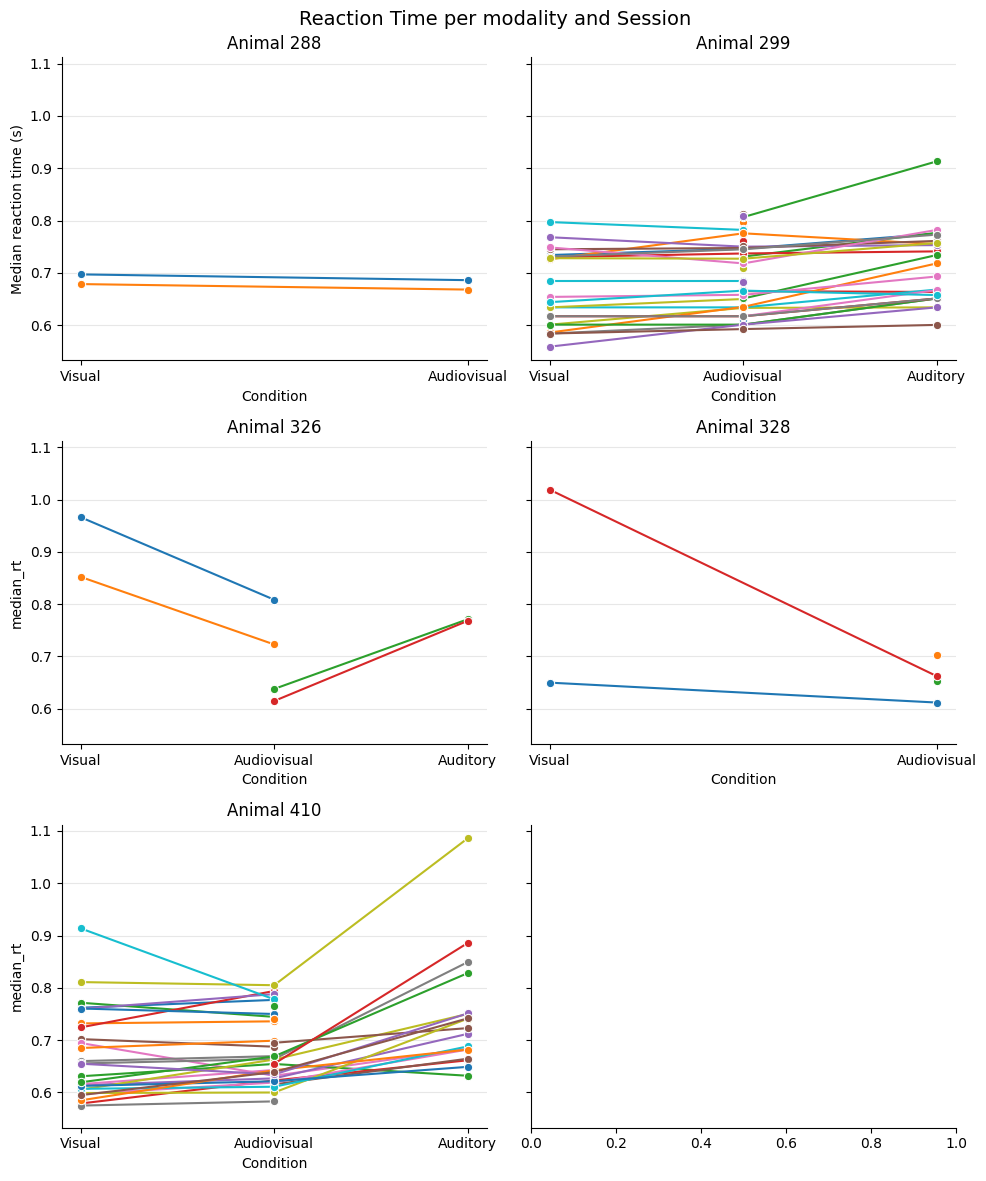

In [141]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Define comparison
conditions = ["Visual", "Audiovisual", "Auditory"]

# Get animals
animals = sorted(session_rt["animal_id"].unique())

# Create one subplot per animal
fig, axes = plt.subplots(
    3,
    2,
    figsize=(10,12),
    sharey=True,
    squeeze=False,
)

axes = axes.flatten()

for ax, animal_id in zip(axes, animals):

    # Filter one animal and the two modalities
    plot_df = session_rt[
        (session_rt["animal_id"] == animal_id)
        & (session_rt["modality"].isin(conditions))
    ].copy()

    # Ensure consistent condition order
    plot_df["modality"] = pd.Categorical(
        plot_df["modality"],
        categories=conditions,
        ordered=True,
    )

    # Connect the two modality measurements belonging to each session
    sns.lineplot(
        data=plot_df,
        x="modality",
        y="median_rt",
        hue="session",
        units="session",
        estimator=None,
        marker="o",
        palette="tab10",
        legend=False,
        ax=ax,
    )

    ax.set_title(f"Animal {animal_id}")
    ax.set_xlabel("Condition")
    ax.grid(axis="y", alpha=0.3)

axes[0].set_ylabel("Median reaction time (s)")

fig.suptitle(
    "Reaction Time per modality and Session",
    fontsize=14,
)
sns.despine()
plt.tight_layout()
plt.show()

The above script create a lineplot comparing the reaction time between modality across sessions for all animal ids <b> only for sessions in which I have the multimodal effect</b>

#### What is the overall RT distribution for each modality across all recorded trials?

In [58]:
# meadn_rt, median_rt, sd_rt and n_trials calculated from all trials pooled across all animals
rt_summary = round(
    session_rt_filtered
    .groupby("modality")["rt"]
    .agg(
        mean_rt="mean",
        median_rt="median",
        sd_rt="std",
        n_trials="count",
    )
    .reset_index(),3
)

rt_summary

,modality,mean_rt,median_rt,sd_rt,n_trials
0,Audiovisual,0.723,0.687,0.216,54784
1,Auditory,0.825,0.749,0.296,6494
2,Visual,0.739,0.694,0.221,7816


#### What is the overall RT distribution for each modality across all recorded sessions taking into account the animal_id too?

DataFrame summarizes reaction times for each `animal_id` and `modality`.

In [59]:
# mean_rt, median_rt, sd_rt and n_trials per condition and animal across sessions
rt_by_animal = (
    session_rt_filtered
    .groupby(["animal_id", "modality"])["rt"]
    .agg(
        mean_rt="mean",
        median_rt="median",
        sd_rt="std",
        n_trials="count",
    )
    .reset_index()
    .round(3)
)

rt_by_animal

,animal_id,modality,mean_rt,median_rt,sd_rt,n_trials
0,288,Audiovisual,0.725,0.696,0.139,10736
1,288,Auditory,0.798,0.736,0.227,516
2,288,Visual,0.722,0.692,0.120,762
3,299,Audiovisual,0.775,0.753,0.170,18582
4,299,Auditory,0.786,0.750,0.202,3267
5,299,Visual,0.738,0.718,0.164,3651
6,324,Audiovisual,0.648,0.634,0.268,8858
7,324,Auditory,0.810,0.749,0.403,392
8,324,Visual,0.658,0.644,0.272,460
9,326,Audiovisual,0.711,0.655,0.204,3598


#### paired t-test
> visual Vs audiovisual &
> Auditory Vs audiovisual

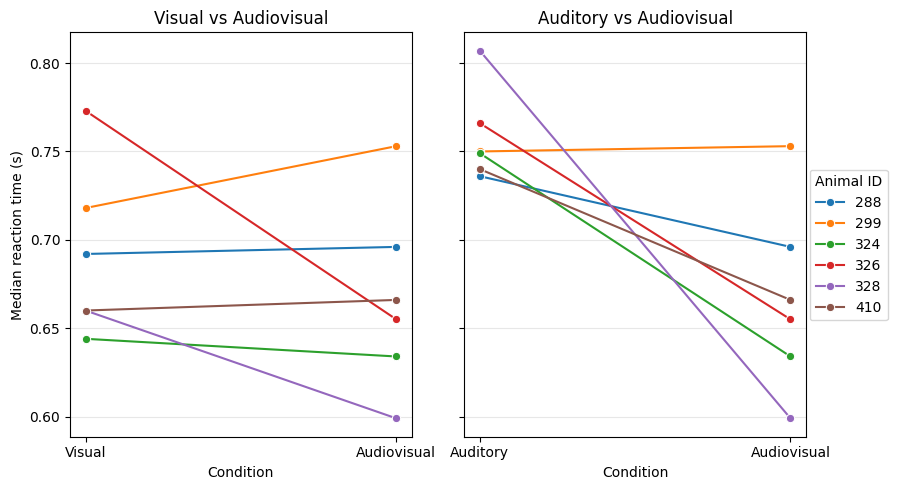

In [60]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Define the comparisons
comparisons = [
    ["Visual", "Audiovisual"],
    ["Auditory", "Audiovisual"]
]

# Consistent animal colors
animals = sorted(rt_by_animal["animal_id"].unique()
)
animal_palette = dict(
    zip(animals, sns.color_palette("tab10", n_colors=len(animals)))
)

fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True)

for i, (ax, conditions) in enumerate(zip(axes, comparisons)):

    # Filter conditions
    plot_df = rt_by_animal[
        rt_by_animal["modality"].isin(conditions)
    ].copy()

    # Ensure consistent condition order
    plot_df["modality"] = pd.Categorical(
        plot_df["modality"],
        categories=conditions,
        ordered=True
    )

    # Connect dots belonging to the same animal
    sns.lineplot(
        data=plot_df,
        x="modality",
        y="median_rt",
        hue="animal_id",
        palette=animal_palette,
        units="animal_id",
        estimator=None,
        marker="o",
        legend=(i == 0),
        ax=ax
    )

    ax.set_title(f"{conditions[0]} vs {conditions[1]}")
    ax.set_xlabel("Condition")
    ax.grid(axis="y", alpha=0.3)

    # Extract legend from first subplot
    if i == 0:
        handles, labels = ax.get_legend_handles_labels()
        ax.get_legend().remove()

# Shared y-axis label
axes[0].set_ylabel("Median reaction time (s)")

# One shared legend
fig.legend(
    handles,
    labels,
    title="Animal ID",
    loc="center right",
    bbox_to_anchor=(0.9, 0.5)
)

plt.tight_layout(rect=[0, 0, 0.85, 1])
plt.show()

In [61]:
from scipy.stats import ttest_rel
import pandas as pd

comparisons = [
    ("Visual", "Audiovisual"),
    ("Auditory", "Audiovisual"),
    ("Visual", "Auditory")
]

results = []

for condition1, condition2 in comparisons:

    paired_df = (
        rt_by_animal[
            rt_by_animal["modality"].isin([condition1, condition2])
        ]
        .pivot(
            index="animal_id",
            columns="modality",
            values="median_rt"
        )
        .dropna(subset=[condition1, condition2])
    )

    t_stat, p_value = ttest_rel(
        paired_df[condition1],
        paired_df[condition2]
    )

    results.append({
        "comparison": f"{condition1} vs {condition2}",
        "n_animals": len(paired_df),
        "t_statistic": t_stat,
        "p_value": p_value,
        "result": "Significant" if p_value < 0.05 else "Not significant"
    })

results_df = pd.DataFrame(results).round(4)

results_df

,comparison,n_animals,t_statistic,p_value,result
0,Visual vs Audiovisual,6,1.0536,0.3403,Not significant
1,Auditory vs Audiovisual,6,3.0625,0.0280,Significant
2,Visual vs Auditory,6,-2.9650,0.0313,Significant


In [62]:
rt_across_animals = (
    rt_by_animal
    .groupby("modality")
    .agg(
        mean_of_animal_means=("mean_rt", "mean"),
        mean_of_animal_medians=("median_rt", "mean"),
        median_of_animal_medians=("median_rt", "median"),
        sd_across_animals=("median_rt", "std"),
        n_animals=("animal_id", "nunique"),
    )
    .reset_index()
    .round(3)
)

rt_across_animals

,modality,mean_of_animal_means,mean_of_animal_medians,median_of_animal_medians,sd_across_animals,n_animals
0,Audiovisual,0.711,0.667,0.661,0.053,6
1,Auditory,0.856,0.758,0.750,0.026,6
2,Visual,0.742,0.691,0.676,0.048,6


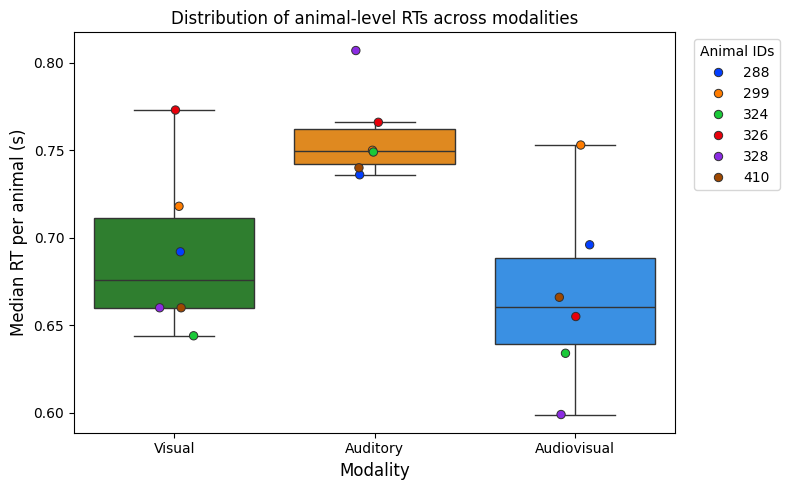

In [63]:
box_colors = {
    "Visual": "forestgreen",
    "Auditory": "darkorange",
    "Audiovisual": "dodgerblue",
}
# box_colors = {
#     "Visual": "green",
#     "Auditory": "orange",
#     "Audiovisual": "blue",
# }

fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(
    data=rt_by_animal,
    x="modality",
    y="median_rt",
    order=["Visual", "Auditory", "Audiovisual"],
    hue="modality",
    palette=box_colors,
    # boxprops={"alpha": 0.5},
    fliersize=0,
    ax=ax,
)

sns.stripplot(
    data=rt_by_animal,
    x="modality",
    y="median_rt",
    order=["Visual", "Auditory", "Audiovisual"],
    hue="animal_id",
    palette = "bright",
    linewidth=0.7,
    jitter=0.1,
    size=6,
    ax=ax,
)

ax.set_xlabel("Modality", fontsize=12)
ax.set_ylabel("Median RT per animal (s)", fontsize=12)
ax.set_title("Distribution of animal-level RTs across modalities")
ax.legend(title="Animal IDs", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

Each dot represents the median in each condition per animal id.

### Reaction Interval between <b> stimulus onset & response state</b> - <u>Audiovisual difficult trials</u>

In [1012]:
rt_sessions = []

for animal in animals:
    task_type = "audiovisual_diff"
    excluded_sessions = []

    # Get the behavioral sessions available for the selected animal and task.
    sessions_idx = get_behavior_sessions(animal_id=animal, task_type=task_type)

    # Exclude sessions if necessary.
    sessions_idx = [
        session for session in sessions_idx if session not in excluded_sessions
    ]

    for session in sessions_idx:
        key = {"animal_id": animal, "session": session}

        # unimodal-visual trials
        vis_trials = (
            (
                stim.StimCondition.Trial
                * (stim.Panda.Object).proj("obj_mag")
                * exp.Trial.StateOnset
                * (stim.Tones).proj("tone_volume")
                & "tone_volume = 0"
                & "obj_id NOT IN (214,216,217)"
                & key
                & 'state IN ("Reward", "Punish")'
            )
            .fetch(format="frame")
            .reset_index()
        )

        vis_trials["obj_mag"] = pd.to_numeric(vis_trials["obj_mag"], errors="coerce")
        vis_trials = vis_trials.loc[vis_trials["obj_mag"] > 0].copy()

        # unimodal-auditory trials
        auditory_trials = (
            (
                stim.StimCondition.Trial
                * (stim.Panda.Object).proj("obj_mag")
                * exp.Trial.StateOnset
                * (stim.Tones).proj("tone_volume")
                & "tone_volume > 0"
                & key
                & 'state IN ("Reward", "Punish")'
            )
            .fetch(format="frame")
            .reset_index()
        )

        auditory_trials["obj_mag"] = pd.to_numeric(
            auditory_trials["obj_mag"], errors="coerce"
        )
        auditory_trials = auditory_trials.loc[auditory_trials["obj_mag"] == 0].copy()

        # audiovisual trials
        multi_trials = (
            (
                stim.StimCondition.Trial
                * (stim.Panda.Object).proj("obj_mag")
                * exp.Trial.StateOnset
                * (stim.Tones).proj("tone_volume")
                & "tone_volume > 0"
                & "obj_id NOT IN (214,216,217)"
                & key
                & 'state IN ("Reward", "Punish")'
            )
            .fetch(format="frame")
            .reset_index()
        )

        multi_trials["obj_mag"] = pd.to_numeric(
            multi_trials["obj_mag"], errors="coerce"
        )
        multi_trials = multi_trials.loc[multi_trials["obj_mag"] > 0].copy()

        # audiovisual difficult trials
        multi_diff_trials = (
            (
                stim.StimCondition.Trial
                * (stim.Panda.Object).proj("obj_mag")
                * exp.Trial.StateOnset
                * (stim.Tones).proj("tone_volume")
                & "tone_volume > 0"
                & "obj_id IN (214,216,217)"
                & key
                & 'state IN ("Reward", "Punish")'
            )
            .fetch(format="frame")
            .reset_index()
        )
        
        multi_diff_trials["obj_mag"] = pd.to_numeric(
            multi_diff_trials["obj_mag"], errors="coerce"
        )
        multi_diff_trials = multi_diff_trials.loc[multi_diff_trials["obj_mag"] > 0].copy()

        # visual difficult trials
        vis_diff_trials = (
            (
                stim.StimCondition.Trial
                * (stim.Panda.Object).proj("obj_mag")
                * exp.Trial.StateOnset
                * (stim.Tones).proj("tone_volume")
                & "tone_volume = 0"
                & "obj_id IN (214,216,217)"
                & key
                & 'state IN ("Reward", "Punish")'
            )
            .fetch(format="frame")
            .reset_index()
        )
        
        vis_diff_trials["obj_mag"] = pd.to_numeric(
            vis_diff_trials["obj_mag"], errors="coerce"
        )
        vis_diff_trials = vis_diff_trials.loc[vis_diff_trials["obj_mag"] > 0].copy()

        

        # Calculate reaction time and label each condition
        for df, modality in [
            (vis_trials, "Visual"),
            (auditory_trials, "Auditory"),
            (multi_trials, "AV"),
            (vis_diff_trials, "Visual diff"),
            (multi_diff_trials, "AV diff"),
        ]:
            df = df.copy()

            df = df.rename(
                columns={
                    "start_time": "stim_onset",
                    "time": "response_onset",
                }
            )

            df["rt"] = (df["response_onset"] - df["stim_onset"]) / 1000

            df["modality"] = modality

            rt_sessions.append(df)

rt_df = pd.concat(rt_sessions, ignore_index=True)

# Remove rows with missing reaction times or modalities.
session_rt = rt_df.dropna(subset=["rt", "modality"]).copy()

# Keep reaction times between 0 and 2.0
session_rt_filtered = session_rt.loc[(session_rt["rt"] > 0) & (session_rt["rt"] <= 2.0)].copy()

# Calculate the median RT for each animal, session, and modality.
session_rt = (
    session_rt_filtered.groupby(["animal_id", "session", "modality"])["rt"]
    .agg(
        median_rt="median",
        n_trials="count",
    )
    .reset_index()
)

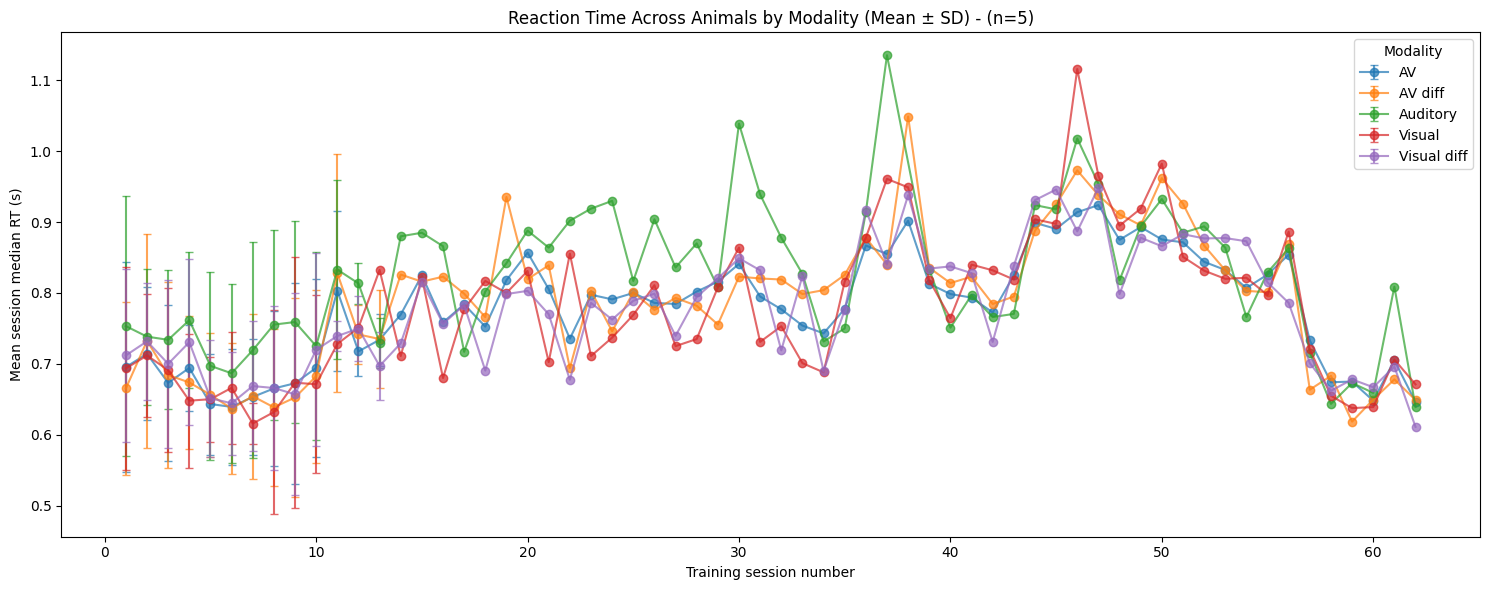

In [1013]:
# Assign consecutive session positions within each animal
session_rt["session_position"] = session_rt.groupby("animal_id")["session"].rank(
    method="dense"
)

# Calculate mean and SD across animals at each position and modality
across_animals = (
    session_rt.groupby(["session_position", "modality"])["median_rt"]
    .agg(
        mean_rt="mean",
        sd_rt="std",
        n_animals="count",
    )
    .reset_index()
)

# Plot mean ± SD
plt.figure(figsize=(15, 6))

for modality, data in across_animals.groupby("modality"):
    data = data.sort_values("session_position")

    plt.errorbar(
        data["session_position"],
        data["mean_rt"],
        yerr=data["sd_rt"],
        marker="o",
        capsize=3,
        linewidth=1.5,
        label=modality,
        alpha=0.7,
    )

plt.xlabel("Training session number")
plt.ylabel("Mean session median RT (s)")
plt.title(f"Reaction Time Across Animals by Modality (Mean ± SD) - (n={len(np.unique(session_rt['animal_id']))})")
plt.legend(title="Modality")

plt.tight_layout()
plt.show()

In [1014]:
rt_by_animal = (
    session_rt_filtered
    .groupby(["animal_id", "modality"])["rt"]
    .agg(
        mean_rt="mean",
        median_rt="median",
        sd_rt="std",
        n_trials="count",
    )
    .reset_index()
    .round(3)
)

rt_by_animal

,animal_id,modality,mean_rt,median_rt,sd_rt,n_trials
0,288,AV,0.736,0.707,0.135,1766
1,288,AV diff,0.730,0.705,0.128,803
2,288,Auditory,0.781,0.723,0.215,163
3,288,Visual,0.713,0.687,0.129,83
4,288,Visual diff,0.730,0.703,0.129,344
5,299,AV,0.825,0.811,0.154,8901
6,299,AV diff,0.812,0.799,0.153,2751
7,299,Auditory,0.887,0.849,0.225,657
8,299,Visual,0.818,0.803,0.159,577
9,299,Visual diff,0.822,0.792,0.180,1468


#### paired t-test
> `visual Vs audiovisual`,
> `Visual Vs visual diff`, `Visual Vs audiovisual diff`, `audiovisual Vs audiovisual diff`

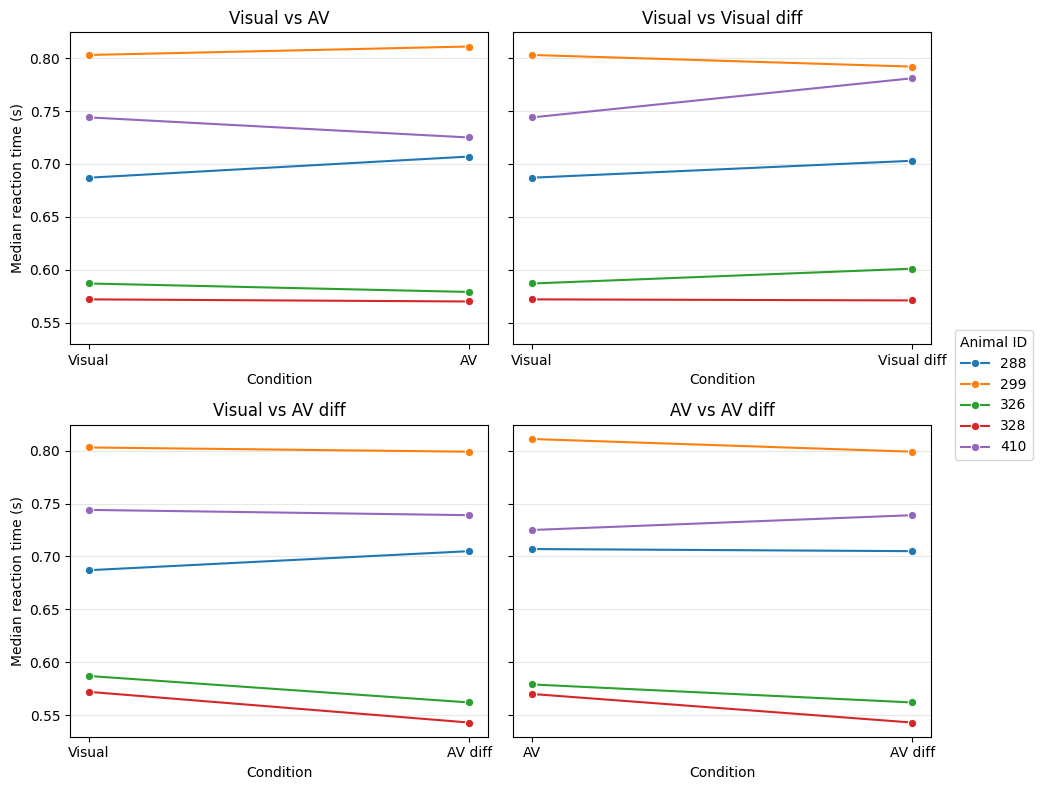

In [1017]:
import matplotlib.pyplot as plt
import seaborn as sns

# Define comparisons
comparisons = [
    ["Visual", "AV"],
    ["Visual", "Visual diff"],
    ["Visual", "AV diff"],
    ["AV", "AV diff"],
]

# Consistent animal colors across all subplots
animals = sorted(rt_by_animal["animal_id"].unique())

animal_palette = dict(
    zip(animals, sns.color_palette("tab10", n_colors=len(animals)))
)

# Create figure
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharey=True)

for i, (ax, conditions) in enumerate(zip(axes.flat, comparisons)):

    plot_df = rt_by_animal[
        rt_by_animal["modality"].isin(conditions)
    ].copy()

    # Ensure consistent condition order
    plot_df["modality"] = pd.Categorical(
        plot_df["modality"],
        categories=conditions,
        ordered=True
    )

    sns.lineplot(
        data=plot_df,
        x="modality",
        y="median_rt",
        hue="animal_id",
        palette=animal_palette,
        units="animal_id",
        estimator=None,
        marker="o",
        legend=(i == 0),
        ax=ax
    )

    ax.set_title(" vs ".join(conditions))
    ax.set_xlabel("Condition")
    ax.grid(axis="y", alpha=0.3)

    # Extract handles and labels from the first subplot
    if i == 0:
        handles, labels = ax.get_legend_handles_labels()
        ax.get_legend().remove()

# Y-axis labels
axes[0, 0].set_ylabel("Median reaction time (s)")
axes[1, 0].set_ylabel("Median reaction time (s)")

# Add one shared legend
fig.legend(
    handles,
    labels,
    title="Animal ID",
    loc="center right",
    bbox_to_anchor=(0.95, 0.5)
)

plt.tight_layout(rect=[0, 0, 0.88, 1])
plt.show()

In [1018]:
from scipy.stats import ttest_rel
import pandas as pd

comparisons = [
    ("Visual", "Visual diff"),
    ("Visual", "AV"),
    ("Visual", "AV diff"),
    ("AV", "AV diff"),
    ("Auditory", "Visual")
    
]

results = []

for condition1, condition2 in comparisons:

    paired_df = (
        rt_by_animal[
            rt_by_animal["modality"].isin([condition1, condition2])
        ]
        .pivot(
            index="animal_id",
            columns="modality",
            values="median_rt"
        )
        .dropna(subset=[condition1, condition2])
    )

    t_stat, p_value = ttest_rel(
        paired_df[condition1],
        paired_df[condition2]
    )

    results.append({
        "comparison": f"{condition1} vs {condition2}",
        "n_animals": len(paired_df),
        "t_statistic": t_stat,
        "p_value": p_value,
        "result": "Significant" if p_value < 0.05 else "Not significant"
    })

results_df = pd.DataFrame(results).round(4)

results_df

,comparison,n_animals,t_statistic,p_value,result
0,Visual vs Visual diff,5,-1.3449,0.2499,Not significant
1,Visual vs AV,5,0.0299,0.9776,Not significant
2,Visual vs AV diff,5,1.0659,0.3466,Not significant
3,AV vs AV diff,5,1.2605,0.2760,Not significant
4,Auditory vs Visual,5,1.2977,0.2642,Not significant


In [538]:
rt_across_animals = (
    rt_by_animal
    .groupby("modality")
    .agg(
        mean_of_animal_means=("mean_rt", "mean"),
        mean_of_animal_medians=("median_rt", "mean"),
        median_of_animal_medians=("median_rt", "median"),
        sd_across_animals=("median_rt", "std"),
        n_animals=("animal_id", "nunique"),
    )
    .reset_index()
    .round(3)
)

rt_across_animals

,modality,mean_of_animal_means,mean_of_animal_medians,median_of_animal_medians,sd_across_animals,n_animals
0,AV,0.711,0.678,0.707,0.103,5
1,AV diff,0.706,0.670,0.705,0.112,5
2,Auditory,0.772,0.714,0.682,0.081,5
3,Visual,0.717,0.679,0.687,0.099,5
4,Visual diff,0.741,0.690,0.703,0.101,5


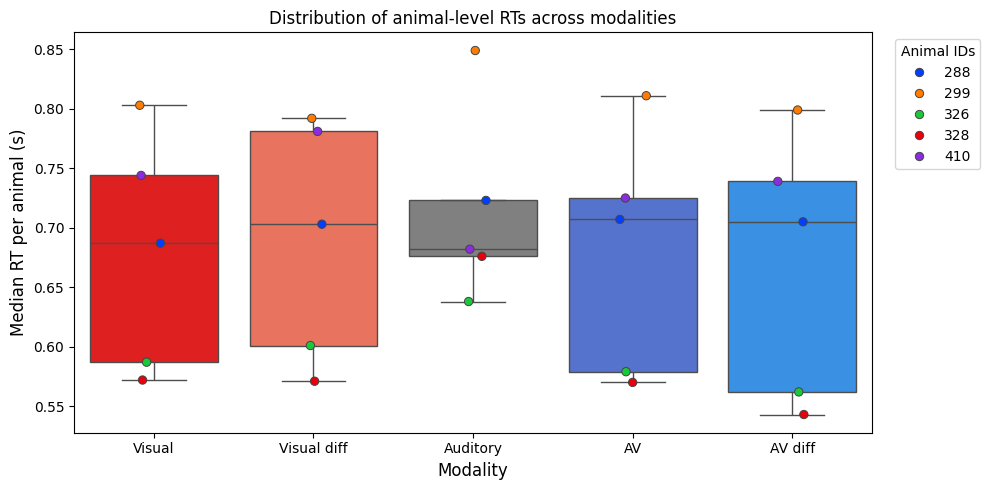

In [543]:
box_colors = {
    "Visual": "red",
    "Visual diff": "tomato",
    "Auditory": "grey",
    "AV": "royalblue",
    "AV diff": "dodgerblue",
}
# box_colors = {
#     "Visual": "green",
#     "Auditory": "orange",
#     "Audiovisual": "blue",
# }

fig, ax = plt.subplots(figsize=(10, 5))

sns.boxplot(
    data=rt_by_animal,
    x="modality",
    y="median_rt",
    order=["Visual", "Visual diff", "Auditory", "AV", "AV diff"],
    hue="modality",
    palette=box_colors,
    # boxprops={"alpha": 0.5},
    fliersize=0,
    ax=ax,
)

sns.stripplot(
    data=rt_by_animal,
    x="modality",
    y="median_rt",
    order=["Visual", "Visual diff", "Auditory", "AV", "AV diff"],
    hue="animal_id",
    palette = "bright",
    linewidth=0.7,
    jitter=0.1,
    size=6,
    ax=ax,
)

ax.set_xlabel("Modality", fontsize=12)
ax.set_ylabel("Median RT per animal (s)", fontsize=12)
ax.set_title("Distribution of animal-level RTs across modalities")
ax.legend(title="Animal IDs", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

### Reaction Interval between <b> stimulus onset & response state</b> - <u>Audiovisual conflicted trial</u>

In [983]:
rt_sessions = []

for animal in animals:
    task_type = "audiovisual_conflicted"
    excluded_sessions = []

    # Get the behavioral sessions available for the selected animal and task.
    sessions_idx = get_behavior_sessions(animal_id=animal, task_type=task_type)

    # Exclude sessions if necessary.
    sessions_idx = [
        session for session in sessions_idx if session not in excluded_sessions
    ]

    for session in sessions_idx:
        key = {"animal_id": animal, "session": session}

        # unimodal-visual trials
        vis_trials = (
            (
                stim.StimCondition.Trial
                * (stim.Panda.Object).proj("obj_mag")
                * exp.Trial.StateOnset
                * (stim.Tones).proj("tone_volume")
                & "tone_volume = 0"
                & "obj_id NOT IN (214,216,217)"
                & key
                & 'state IN ("Reward", "Punish")'
            )
            .fetch(format="frame")
            .reset_index()
        )

        vis_trials["obj_mag"] = pd.to_numeric(vis_trials["obj_mag"], errors="coerce")
        vis_trials = vis_trials.loc[vis_trials["obj_mag"] > 0].copy()

        # unimodal-auditory trials
        auditory_trials = (
            (
                stim.StimCondition.Trial
                * (stim.Panda.Object).proj("obj_mag")
                * exp.Trial.StateOnset
                * (stim.Tones).proj("tone_volume")
                & "tone_volume > 0"
                & key
                & 'state IN ("Reward", "Punish")'
            )
            .fetch(format="frame")
            .reset_index()
        )

        auditory_trials["obj_mag"] = pd.to_numeric(
            auditory_trials["obj_mag"], errors="coerce"
        )
        auditory_trials = auditory_trials.loc[auditory_trials["obj_mag"] == 0].copy()

        normal_mapping = {
            218: 0,
            219: 0,
            212: 100,
            213: 100,
        }

        # audiovisual trials
        multi_trials = (
            (
                stim.StimCondition.Trial
                * (stim.Panda.Object).proj("obj_mag")
                * exp.Trial.StateOnset
                * (stim.Tones).proj("tone_volume", "tone_pulse_freq")
                & "tone_volume > 0"
                & "obj_id NOT IN (214,216,217)"
                & key
                & 'state IN ("Reward", "Punish")'
            )
            .fetch(format="frame")
            .reset_index()
        )

        multi_trials["obj_mag"] = pd.to_numeric(
            multi_trials["obj_mag"], errors="coerce"
        )
        multi_trials = multi_trials.loc[multi_trials["obj_mag"] > 0].copy()
        
        # Classify audiovisual trials
        multi_trials["expected_tone"] = multi_trials["obj_id"].map(
            normal_mapping
        )
        
        multi_trials["modality"] = np.where(
            multi_trials["tone_pulse_freq"] == multi_trials["expected_tone"],
            "AV",
            "AV conflicted"
        )

        # Normal audiovisual trials
        multi_normal = multi_trials[
            multi_trials["modality"] == "AV"
        ].copy()
        
        # Incongruent audiovisual trials - Rewarded
        multi_incongr_rew = multi_trials[
            (multi_trials["modality"] == "AV conflicted") &
            (multi_trials["state"] == "Reward")
        ].copy()
        
        # Incongruent audiovisual trials - Punished
        multi_incongr_pun = multi_trials[
            (multi_trials["modality"] == "AV conflicted") &
            (multi_trials["state"] == "Punish")
        ].copy()

        # Calculate reaction time and label each condition
        for df, modality in [
            (vis_trials, "Visual"),
            (auditory_trials, "Auditory"),
            (multi_normal, "AV Congruent"),
            (multi_incongr_rew, "AV Incongruent (Rew)"),
            (multi_incongr_pun, "AV Incongruent (Pun)"),
        ]:
            df = df.copy()

            df = df.rename(
                columns={
                    "start_time": "stim_onset",
                    "time": "response_onset",
                }
            )

            df["rt"] = (df["response_onset"] - df["stim_onset"]) / 1000

            df["modality"] = modality

            rt_sessions.append(df)

rt_df = pd.concat(rt_sessions, ignore_index=True)

# Remove rows with missing reaction times or modalities.
session_rt = rt_df.dropna(subset=["rt", "modality"]).copy()

# Keep reaction times between 0 and 2.0
session_rt_filtered = session_rt.loc[(session_rt["rt"] > 0) & (session_rt["rt"] <= 5.0)].copy()

# Calculate the median RT for each animal, session, and modality.
session_rt = (
    session_rt_filtered.groupby(["animal_id", "session", "modality"])["rt"]
    .agg(
        median_rt="median",
        n_trials="count",
    )
    .reset_index()
)

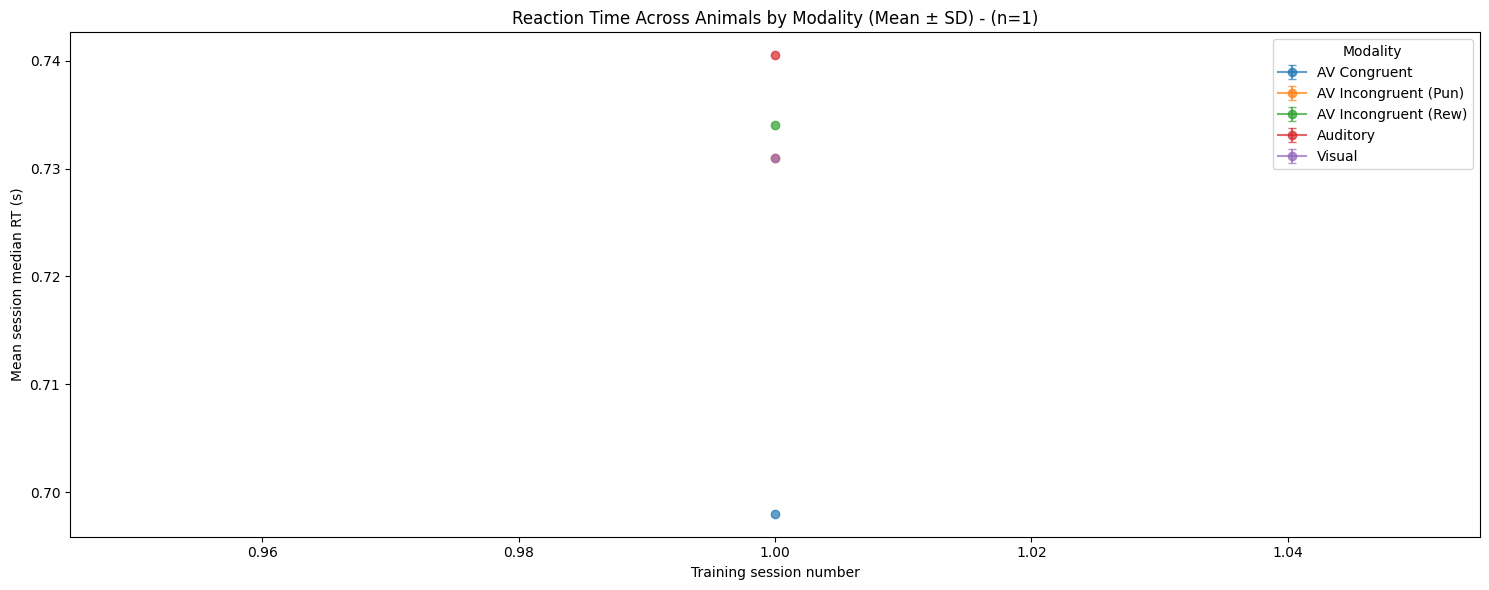

In [984]:
# Assign consecutive session positions within each animal
session_rt["session_position"] = session_rt.groupby("animal_id")["session"].rank(
    method="dense"
)

# Calculate mean and SD across animals at each position and modality
across_animals = (
    session_rt.groupby(["session_position", "modality"])["median_rt"]
    .agg(
        mean_rt="mean",
        sd_rt="std",
        n_animals="count",
    )
    .reset_index()
)

# Plot mean ± SD
plt.figure(figsize=(15, 6))

for modality, data in across_animals.groupby("modality"):
    data = data.sort_values("session_position")

    plt.errorbar(
        data["session_position"],
        data["mean_rt"],
        yerr=data["sd_rt"],
        marker="o",
        capsize=3,
        linewidth=1.5,
        label=modality,
        alpha=0.7,
    )

plt.xlabel("Training session number")
plt.ylabel("Mean session median RT (s)")
plt.title(f"Reaction Time Across Animals by Modality (Mean ± SD) - (n={len(np.unique(session_rt['animal_id']))})")
plt.legend(title="Modality")

plt.tight_layout()
plt.show()

In [985]:
rt_by_animal = (
    session_rt_filtered
    .groupby(["animal_id", "modality"])["rt"]
    .agg(
        mean_rt="mean",
        median_rt="median",
        sd_rt="std",
        n_trials="count",
    )
    .reset_index()
    .round(3)
)

rt_by_animal.head()

,animal_id,modality,mean_rt,median_rt,sd_rt,n_trials
0,299,AV Congruent,0.713,0.698,0.099,123
1,299,AV Incongruent (Pun),0.740,0.731,0.088,41
2,299,AV Incongruent (Rew),0.743,0.734,0.092,41
3,299,Auditory,0.770,0.740,0.254,32
4,299,Visual,0.732,0.731,0.180,40


#### Pair-samples t-test analysis

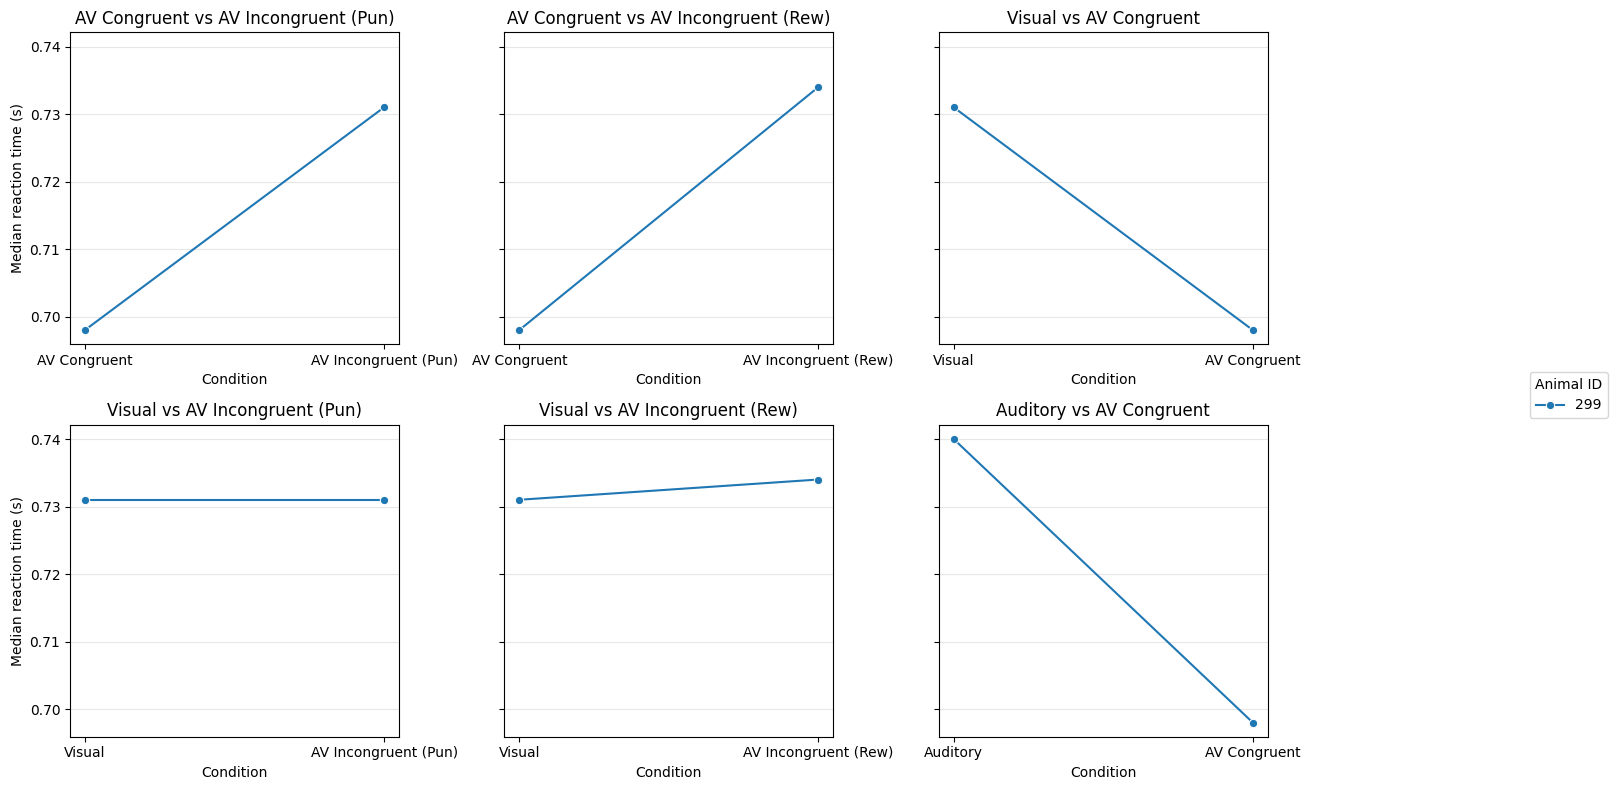

In [986]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# ===================== Define comparisons =====================

comparisons = [
    ["AV Congruent", "AV Incongruent (Pun)"],
    ["AV Congruent", "AV Incongruent (Rew)"],
    ["Visual", "AV Congruent"],
    ["Visual", "AV Incongruent (Pun)"],
    ["Visual", "AV Incongruent (Rew)"],
    ["Auditory", "AV Congruent"],
]

# ===================== Consistent animal colors =====================

animals = sorted(rt_by_animal["animal_id"].unique())

animal_palette = dict(
    zip(
        animals,
        sns.color_palette("tab10", n_colors=len(animals))
    )
)

# ===================== Create figure =====================

fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 8),
    sharey=True
)

for i, (ax, conditions) in enumerate(zip(axes.flat, comparisons)):

    # Select the two conditions for this comparison
    plot_df = rt_by_animal[
        rt_by_animal["modality"].isin(conditions)
    ].copy()

    # Enforce the order of conditions on the x-axis
    plot_df["modality"] = pd.Categorical(
        plot_df["modality"],
        categories=conditions,
        ordered=True
    )

    # Plot one line per animal
    sns.lineplot(
        data=plot_df,
        x="modality",
        y="median_rt",
        hue="animal_id",
        palette=animal_palette,
        units="animal_id",
        estimator=None,
        marker="o",
        legend=(i == 0),
        ax=ax
    )

    ax.set_title(" vs ".join(conditions))
    ax.set_xlabel("Condition")
    ax.grid(axis="y", alpha=0.3)

    # Extract the legend from the first subplot
    if i == 0:
        handles, labels = ax.get_legend_handles_labels()
        ax.get_legend().remove()

# ===================== Axis labels =====================

axes[0, 0].set_ylabel("Median reaction time (s)")
axes[1, 0].set_ylabel("Median reaction time (s)")

# ===================== Shared legend =====================

fig.legend(
    handles,
    labels,
    title="Animal ID",
    loc="center right",
    bbox_to_anchor=(1.08, 0.5)
)

plt.tight_layout(rect=[0, 0, 0.88, 1])
plt.show()

In [987]:
print(rt_by_animal["modality"].unique())

['AV Congruent' 'AV Incongruent (Pun)' 'AV Incongruent (Rew)' 'Auditory'
 'Visual']


In [989]:
from scipy.stats import ttest_rel
import pandas as pd
import numpy as np

comparisons = [
    ("AV Congruent", "AV Incongruent (Pun)"),
    ("AV Congruent", "AV Incongruent (Rew)"),
    ("AV Congruent", "Visual"),
    ("Visual", "AV Incongruent (Pun)"),
    ("Auditory", "Visual")
]

results = []

for condition1, condition2 in comparisons:

    paired_df = (
        rt_by_animal[
            rt_by_animal["modality"].isin([condition1, condition2])
        ]
        .pivot(
            index="animal_id",
            columns="modality",
            values="median_rt"
        )
        .dropna(subset=[condition1, condition2])
    )

    differences = paired_df[condition1] - paired_df[condition2]

    print(f"\n{condition1} vs {condition2}")
    print(f"Number of animals: {len(paired_df)}")
    print("Paired differences:")
    print(differences)
    print(f"Mean difference: {differences.mean():.6f}")
    print(f"SD of differences: {differences.std():.6f}")

    if len(differences) < 2 or np.isclose(differences.std(), 0):
        print("Cannot reliably calculate paired t-test.")
        continue

    t_stat, p_value = ttest_rel(
        paired_df[condition1],
        paired_df[condition2]
    )

    results.append({
        "comparison": f"{condition1} vs {condition2}",
        "n_animals": len(paired_df),
        "mean_difference": differences.mean(),
        "sd_difference": differences.std(),
        "t_statistic": t_stat,
        "p_value": p_value,
        "result": "Significant" if p_value < 0.05 else "Not significant"
    })

results_df = pd.DataFrame(results).round(4)


AV Congruent vs AV Incongruent (Pun)
Number of animals: 1
Paired differences:
animal_id
299   -0.033
dtype: float64
Mean difference: -0.033000
SD of differences: nan
Cannot reliably calculate paired t-test.

AV Congruent vs AV Incongruent (Rew)
Number of animals: 1
Paired differences:
animal_id
299   -0.036
dtype: float64
Mean difference: -0.036000
SD of differences: nan
Cannot reliably calculate paired t-test.

AV Congruent vs Visual
Number of animals: 1
Paired differences:
animal_id
299   -0.033
dtype: float64
Mean difference: -0.033000
SD of differences: nan
Cannot reliably calculate paired t-test.

Visual vs AV Incongruent (Pun)
Number of animals: 1
Paired differences:
animal_id
299    0.0
dtype: float64
Mean difference: 0.000000
SD of differences: nan
Cannot reliably calculate paired t-test.

Auditory vs Visual
Number of animals: 1
Paired differences:
animal_id
299    0.009
dtype: float64
Mean difference: 0.009000
SD of differences: nan
Cannot reliably calculate paired t-test.


In [988]:
from scipy.stats import ttest_rel
import pandas as pd

comparisons = [
    ("AV Congruent", "AV Incongruent (Pun)"),
    ("AV Congruent", "AV Incongruent (Rew)"),
    ("AV Congruent", "Visual"),
    ("Visual", "AV Incongruent (Pun)"),
    ("Auditory", "Visual")
    
]

results = []

for condition1, condition2 in comparisons:

    paired_df = (
        rt_by_animal[
            rt_by_animal["modality"].isin([condition1, condition2])
        ]
        .pivot(
            index="animal_id",
            columns="modality",
            values="median_rt"
        )
        .dropna(subset=[condition1, condition2])
    )

    t_stat, p_value = ttest_rel(
        paired_df[condition1],
        paired_df[condition2]
    )

    results.append({
        "comparison": f"{condition1} vs {condition2}",
        "n_animals": len(paired_df),
        "t_statistic": t_stat,
        "p_value": p_value,
        "result": "Significant" if p_value < 0.05 else "Not significant"
    })

results_df = pd.DataFrame(results).round(4)

results_df

/home/jupyter-anastasios/.local/lib/python3.10/site-packages/scipy/stats/_axis_nan_policy.py:502: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
/home/jupyter-anastasios/.local/lib/python3.10/site-packages/scipy/stats/_stats_py.py:1214: RuntimeWarning: divide by zero encountered in divide
  var *= np.divide(n, n-ddof)  # to avoid error on division by zero
/home/jupyter-anastasios/.local/lib/python3.10/site-packages/scipy/stats/_stats_py.py:1214: RuntimeWarning: invalid value encountered in scalar multiply
  var *= np.divide(n, n-ddof)  # to avoid error on division by zero
/home/jupyter-anastasios/.local/lib/python3.10/site-packages/scipy/stats/_axis_nan_policy.py:502: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may 

,comparison,n_animals,t_statistic,p_value,result
0,AV Congruent vs AV Incongruent (Pun),1,NaN,NaN,Not significant
1,AV Congruent vs AV Incongruent (Rew),1,NaN,NaN,Not significant
2,AV Congruent vs Visual,1,NaN,NaN,Not significant
3,Visual vs AV Incongruent (Pun),1,NaN,NaN,Not significant
4,Auditory vs Visual,1,NaN,NaN,Not significant


In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 3))

ax.axis("off")

table = ax.table(
    cellText=results_df.values,
    colLabels=results_df.columns,
    cellLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.8)

plt.title("Paired-samples t-test results", pad=20)
plt.tight_layout()
plt.show()

In [663]:
rt_across_animals = (
    rt_by_animal
    .groupby("modality")
    .agg(
        mean_of_animal_means=("mean_rt", "mean"),
        mean_of_animal_medians=("median_rt", "mean"),
        median_of_animal_medians=("median_rt", "median"),
        sd_across_animals=("median_rt", "std"),
        n_animals=("animal_id", "nunique"),
    )
    .reset_index()
    .round(3)
)

rt_across_animals

,modality,mean_of_animal_means,mean_of_animal_medians,median_of_animal_medians,sd_across_animals,n_animals
0,AV Congruent,0.713,0.698,0.698,NaN,1
1,AV Incongruent (Pun),0.740,0.731,0.731,NaN,1
2,AV Incongruent (Rew),0.743,0.734,0.734,NaN,1
3,Auditory,0.770,0.740,0.740,NaN,1
4,Visual,0.732,0.731,0.731,NaN,1


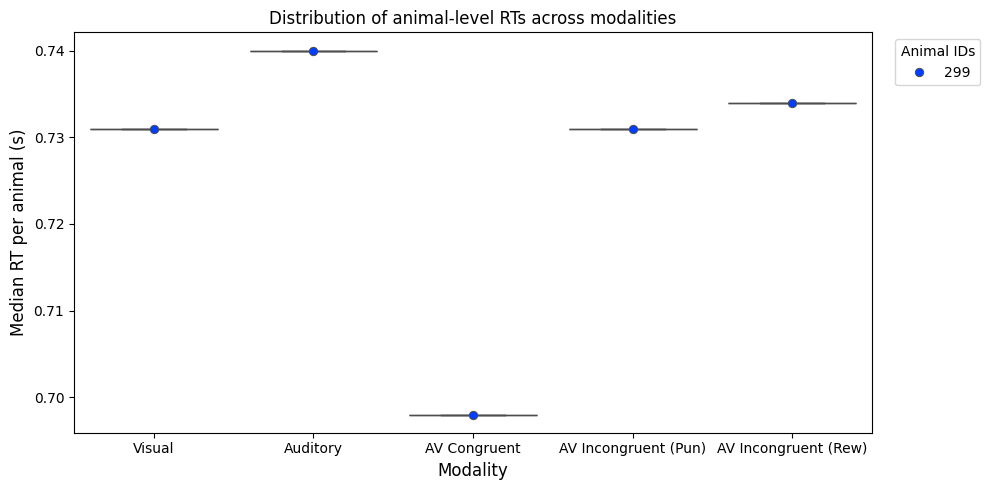

In [940]:
box_colors = {
    "Visual": "red",
    "AV Incongruent (Pun)": "tomato",
    "Auditory": "grey",
    "AV Congruent": "royalblue",
    "AV Incongruent (Rew)": "dodgerblue",
}

fig, ax = plt.subplots(figsize=(10, 5))

order=["Visual", "Auditory", "AV Congruent", "AV Incongruent (Pun)", "AV Incongruent (Rew)"]

sns.boxplot(
    data=rt_by_animal,
    x="modality",
    y="median_rt",
    order=order,
    hue="modality",
    palette=box_colors,
    # boxprops={"alpha": 0.5},
    fliersize=0,
    ax=ax,
)

sns.stripplot(
    data=rt_by_animal,
    x="modality",
    y="median_rt",
    order=order,
    hue="animal_id",
    palette = "bright",
    linewidth=0.7,
    jitter=0.1,
    size=6,
    ax=ax,
)

ax.set_xlabel("Modality", fontsize=12)
ax.set_ylabel("Median RT per animal (s)", fontsize=12)
ax.set_title("Distribution of animal-level RTs across modalities")
ax.legend(title="Animal IDs", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

### Reaction Interval between <b> stimulus onset & response state</b> - <u>no stimulus trials</u>

In [855]:
rt_sessions = []

for animal in animals:
    task_type = "audiovisual_no_stim"
    excluded_sessions = []

    # Get the behavioral sessions available for the selected animal and task.
    sessions_idx = get_behavior_sessions(animal_id=animal, task_type=task_type)

    # Exclude sessions if necessary.
    sessions_idx = [
        session for session in sessions_idx if session not in excluded_sessions
    ]

    for session in sessions_idx:
        key = {"animal_id": animal, "session": session}

        # unimodal-visual trials
        vis_trials = (
            (
                stim.StimCondition.Trial
                * (stim.Panda.Object).proj("obj_mag")
                * exp.Trial.StateOnset
                * (stim.Tones).proj("tone_volume")
                & "tone_volume = 0"
                & "obj_id NOT IN (214,216,217)"
                & key
                & 'state IN ("Reward", "Punish")'
            )
            .fetch(format="frame")
            .reset_index()
        )

        vis_trials["obj_mag"] = pd.to_numeric(vis_trials["obj_mag"], errors="coerce")
        vis_trials = vis_trials.loc[vis_trials["obj_mag"] > 0].copy()

        # unimodal-auditory trials
        auditory_trials = (
            (
                stim.StimCondition.Trial
                * (stim.Panda.Object).proj("obj_mag")
                * exp.Trial.StateOnset
                * (stim.Tones).proj("tone_volume")
                & "tone_volume > 0"
                & key
                & 'state IN ("Reward", "Punish")'
            )
            .fetch(format="frame")
            .reset_index()
        )

        auditory_trials["obj_mag"] = pd.to_numeric(
            auditory_trials["obj_mag"], errors="coerce"
        )
        auditory_trials = auditory_trials.loc[auditory_trials["obj_mag"] == 0].copy()

        # audiovisual trials
        multi_trials = (
            (
                stim.StimCondition.Trial
                * (stim.Panda.Object).proj("obj_mag")
                * exp.Trial.StateOnset
                * (stim.Tones).proj("tone_volume")
                & "tone_volume > 0"
                & "obj_id NOT IN (214,216,217)"
                & key
                & 'state IN ("Reward", "Punish")'
            )
            .fetch(format="frame")
            .reset_index()
        )

        multi_trials["obj_mag"] = pd.to_numeric(
            multi_trials["obj_mag"], errors="coerce"
        )
        multi_trials = multi_trials.loc[multi_trials["obj_mag"] > 0].copy()

        # no stimulus rewarded trials
        no_stim_rew = (
            (
                stim.StimCondition.Trial
                * (stim.Panda.Object).proj("obj_mag")
                * exp.Trial.StateOnset
                * (stim.Tones).proj("tone_volume")
                & "tone_volume = 0"
                & key
                & 'state IN ("Reward")'
            )
            .fetch(format="frame")
            .reset_index()
        )

        no_stim_rew["obj_mag"] = pd.to_numeric(
            no_stim_rew["obj_mag"], errors="coerce"
        )
        no_stim_rew = no_stim_rew.loc[no_stim_rew["obj_mag"] == 0].copy()

        # no stimulus punished trials
        no_stim_pun = (
            (
                stim.StimCondition.Trial
                * (stim.Panda.Object).proj("obj_mag")
                * exp.Trial.StateOnset
                * (stim.Tones).proj("tone_volume")
                & "tone_volume = 0"
                & key
                & 'state IN ("Punish")'
            )
            .fetch(format="frame")
            .reset_index()
        )

        no_stim_pun["obj_mag"] = pd.to_numeric(
            no_stim_pun["obj_mag"], errors="coerce"
        )
        no_stim_pun = no_stim_pun.loc[no_stim_pun["obj_mag"] == 0].copy()


        # Calculate reaction time and label each condition
        for df, modality in [
            (vis_trials, "Visual"),
            (auditory_trials, "Auditory"),
            (multi_trials, "AV"),
            (no_stim_pun, "no_stim (Rew)"),
            (no_stim_rew, "no_stim (Pun)"),
        ]:
            df = df.copy()

            df = df.rename(
                columns={
                    "start_time": "stim_onset",
                    "time": "response_onset",
                }
            )

            df["rt"] = (df["response_onset"] - df["stim_onset"]) / 1000

            df["modality"] = modality

            rt_sessions.append(df)

rt_df = pd.concat(rt_sessions, ignore_index=True)

# Remove rows with missing reaction times or modalities.
session_rt = rt_df.dropna(subset=["rt", "modality"]).copy()

# Keep reaction times between 0 and 2.0
session_rt_filtered = session_rt.loc[(session_rt["rt"] > 0) & (session_rt["rt"] <= 2.0)].copy()

# Calculate the median RT for each animal, session, and modality.
session_rt = (
    session_rt_filtered.groupby(["animal_id", "session", "modality"])["rt"]
    .agg(
        median_rt="median",
        n_trials="count",
    )
    .reset_index()
)

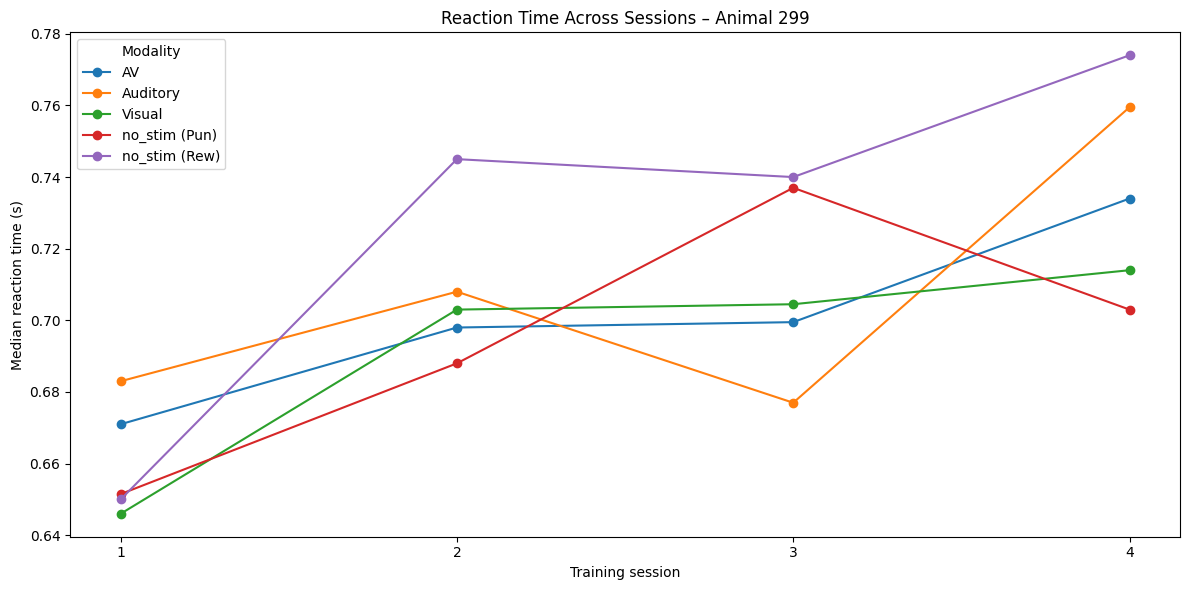

In [856]:
# Assign consecutive session positions (1–4).
session_rt = session_rt.sort_values("session")

session_rt["session_position"] = (
    session_rt["session"].rank(method="dense").astype(int)
)

# Plot session-level median RT for each modality.
fig, ax = plt.subplots(figsize=(12, 6))

for modality, data in session_rt.groupby("modality"):
    data = data.sort_values("session_position")

    ax.plot(
        data["session_position"],
        data["median_rt"],
        marker="o",
        linewidth=1.5,
        label=modality,
    )

ax.set_xlabel("Training session")
ax.set_ylabel("Median reaction time (s)")
ax.set_title(
    f"Reaction Time Across Sessions – Animal {key['animal_id']}"
)
ax.set_xticks(sorted(session_rt["session_position"].unique()))
ax.legend(title="Modality")

plt.tight_layout()
plt.show()

In [857]:
rt_summary = (
    session_rt_filtered
    .groupby("modality")["rt"]
    .agg(
        mean_rt="mean",
        median_rt="median",
        sd_rt="std",
        n_trials="count",
    )
    .reset_index()
    .round(3)
)

rt_summary

,modality,mean_rt,median_rt,sd_rt,n_trials
0,AV,0.711,0.698,0.111,493
1,Auditory,0.736,0.705,0.133,145
2,Visual,0.713,0.702,0.121,122
3,no_stim (Pun),0.716,0.699,0.096,41
4,no_stim (Rew),0.753,0.739,0.119,47


In [858]:
rt_across_animals = (
    rt_by_animal
    .groupby("modality")
    .agg(
        mean_of_animal_means=("mean_rt", "mean"),
        mean_of_animal_medians=("median_rt", "mean"),
        median_of_animal_medians=("median_rt", "median"),
        sd_across_animals=("median_rt", "std"),
        n_animals=("animal_id", "nunique"),
    )
    .reset_index()
    .round(3)
)

rt_across_animals

,modality,mean_of_animal_means,mean_of_animal_medians,median_of_animal_medians,sd_across_animals,n_animals
0,AV Congruent,0.713,0.698,0.698,NaN,1
1,AV Incongruent (Pun),0.740,0.731,0.731,NaN,1
2,AV Incongruent (Rew),0.743,0.734,0.734,NaN,1
3,Auditory,0.770,0.740,0.740,NaN,1
4,Visual,0.732,0.731,0.731,NaN,1


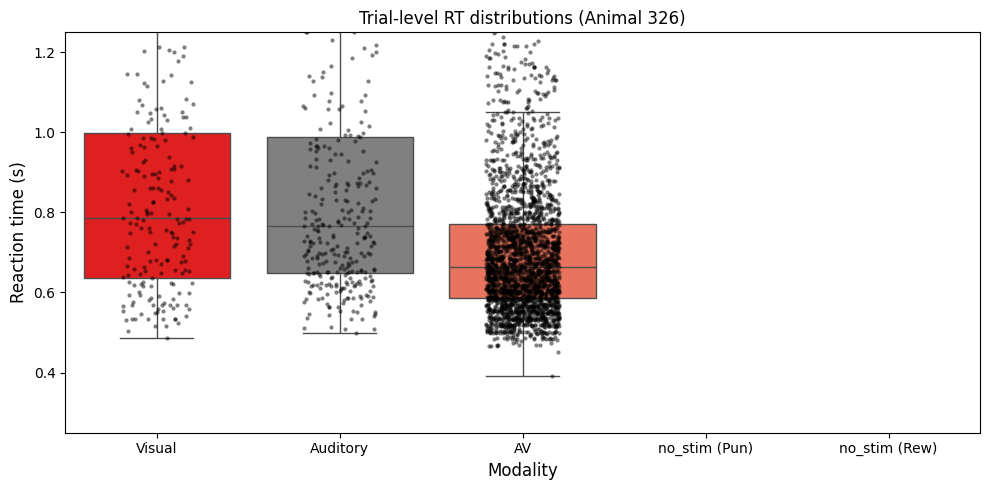

In [792]:
box_colors = {
    "Visual": "red",
    "AV": "tomato",
    "Auditory": "grey",
    "no_stim (Rew)": "royalblue",
    "no_stim (Pun)": "dodgerblue",
}

order = [
    "Visual",
    "Auditory",
    "AV",
    "no_stim (Pun)",
    "no_stim (Rew)",
]

fig, ax = plt.subplots(figsize=(10, 5))

sns.boxplot(
    data=session_rt_filtered,
    x="modality",
    y="rt",
    order=order,
    hue="modality",
    palette=box_colors,
    fliersize=0,
    legend=False,
    ax=ax,
)

sns.stripplot(
    data=session_rt_filtered,
    x="modality",
    y="rt",
    order=order,
    color="black",
    alpha=0.5,
    jitter=0.2,
    size=3,
    ax=ax,
)

ax.set_ylim(0.25, 1.25)
ax.set_xlabel("Modality", fontsize=12)
ax.set_ylabel("Reaction time (s)", fontsize=12)
ax.set_title(f"Trial-level RT distributions (Animal {key['animal_id']})")

plt.tight_layout()
plt.show()

In [793]:
# apply non-parametric Friedman test to evaluate the difference between conditions
from scipy.stats import friedmanchisquare

conditions = [
    "Visual",
    "Auditory",
    "AV",
    # "no_stim (Pun)",
    # "no_stim (Rew)",
]

# Create a session × modality table.
rt_pivot = session_rt.pivot(
    index="session",
    columns="modality",
    values="median_rt",
)

# Keep only sessions containing all five modalities.
rt_complete = rt_pivot[conditions].dropna()

print(rt_complete)

# Friedman test.
statistic, p_value = friedmanchisquare(
    *[rt_complete[condition] for condition in conditions]
)

print(f"Friedman statistic: {statistic:.3f}")
print(f"p-value: {p_value:.5f}")

modality  Visual  Auditory      AV
session                           
57        0.9840    1.1660  0.8050
59        0.9990    1.0830  0.8340
61        0.8250    1.1910  0.7495
63        0.8430    1.0245  0.7160
64        0.7615    0.7415  0.6910
66        0.7520    1.2190  0.7270
68        0.7210    0.9650  0.6960
71        0.6355    0.7710  0.6380
73        0.5655    0.7680  0.6320
76        0.6550    0.8745  0.7000
78        0.5930    0.6490  0.6020
79        0.6175    0.6520  0.5995
94        0.6540    0.6940  0.5805
96        0.5940    0.6640  0.5510
98        0.5610    0.5710  0.5790
100       0.5330    0.7550  0.5505
Friedman statistic: 18.875
p-value: 0.00008


In [794]:
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests
from itertools import combinations

conditions = ["Visual", "Auditory", "AV"]

pairs = list(combinations(conditions, 2))

p_values = []

for cond1, cond2 in pairs:
    statistic, p_value = wilcoxon(
        rt_pivot[cond1],
        rt_pivot[cond2],
        alternative="two-sided"
    )

    p_values.append(p_value)

    print(
        f"{cond1} vs {cond2}: "
        f"statistic={statistic:.3f}, p={p_value:.6f}"
    )

# Holm correction
reject, p_corrected, _, _ = multipletests(
    p_values,
    method="holm"
)

for (cond1, cond2), p_adj, significant in zip(
    pairs, p_corrected, reject
):
    print(
        f"{cond1} vs {cond2}: "
        f"adjusted p={p_adj:.6f}, "
        f"significant={significant}"
    )

Visual vs Auditory: statistic=2.000, p=0.000092
Visual vs AV: statistic=29.500, p=0.050659
Auditory vs AV: statistic=1.000, p=0.000061
Visual vs Auditory: adjusted p=0.000183, significant=True
Visual vs AV: adjusted p=0.050659, significant=False
Auditory vs AV: adjusted p=0.000183, significant=True


In [795]:
rt_pivot[["Visual", "Auditory", "AV"]].median()

modality
Visual      0.6545
Auditory    0.7695
AV          0.6645
dtype: float64

### Data normality

In [670]:
conditions = [
    "Visual",
    "AV Congruent",
    "Auditory",
    "AV Incongruent (Pun)",
    "AV Incongruent (Rew)",
]

rt_pivot = (
    rt_by_animal
    .pivot(index="animal_id", columns="modality", values="median_rt")
    [conditions]
)

# Keep only animals with observations in all five conditions
rt_complete = rt_pivot.dropna()

print("Animals included:", len(rt_complete))

Animals included: 1


/home/jupyter-anastasios/.local/lib/python3.10/site-packages/scipy/stats/_stats_mstats_common.py:182: RuntimeWarning: invalid value encountered in scalar divide
  slope = ssxym / ssxm
/home/jupyter-anastasios/.local/lib/python3.10/site-packages/scipy/stats/_stats_mstats_common.py:196: RuntimeWarning: invalid value encountered in sqrt
  t = r * np.sqrt(df / ((1.0 - r + TINY)*(1.0 + r + TINY)))
/home/jupyter-anastasios/.local/lib/python3.10/site-packages/scipy/stats/_stats_mstats_common.py:199: RuntimeWarning: invalid value encountered in scalar divide
  slope_stderr = np.sqrt((1 - r**2) * ssym / ssxm / df)


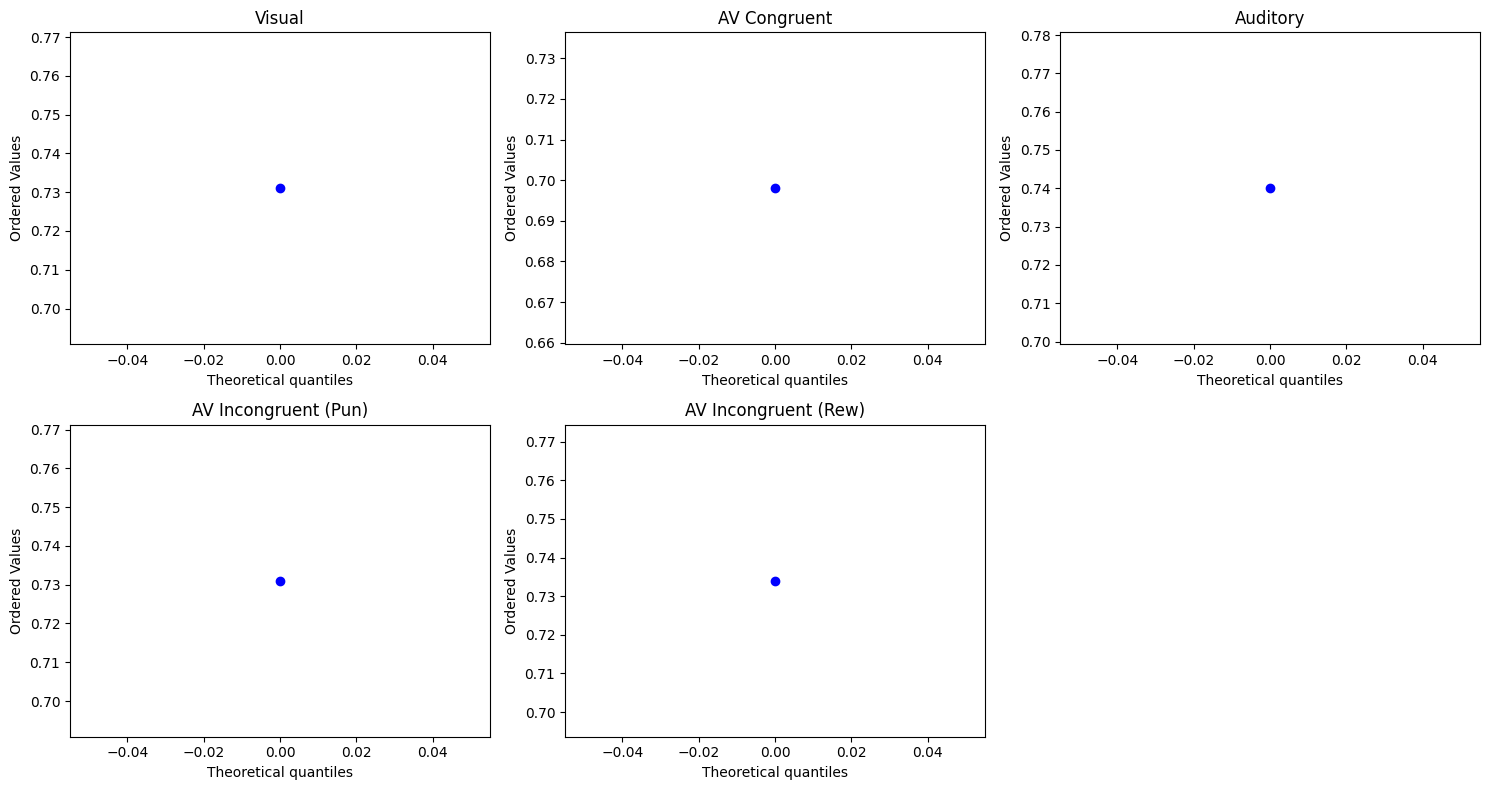

In [671]:
import math
import matplotlib.pyplot as plt
from scipy.stats import probplot

n_conditions = len(conditions)

n_cols = 3
n_rows = math.ceil(n_conditions / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(5 * n_cols, 4 * n_rows),
    squeeze=False
)

for i, condition in enumerate(conditions):
    ax = axes[i // n_cols, i % n_cols]

    probplot(
        rt_complete[condition].dropna(),
        dist="norm",
        plot=ax
    )

    ax.set_title(condition)

# Remove unused subplots
for i in range(n_conditions, n_rows * n_cols):
    fig.delaxes(axes[i // n_cols, i % n_cols])

plt.tight_layout()
plt.show()

# Reaction Intercal between <b> stimulus onset & first lick</b>

In [3]:
animals = get_animal_ids()
print(animals)

['288', '299', '324', '326', '328', '410']


In [4]:
rt_sessions = []

for animal in animals:
    task_type = "audiovisual"
    excluded_sessions = []

    sessions_idx = get_behavior_sessions(
        animal_id=animal,
        task_type=task_type,
    )

    sessions_idx = [
        session for session in sessions_idx
        if session not in excluded_sessions
    ]

    for session in sessions_idx:
        key = {"animal_id": animal, "session": session}

        # ===================== Fetch stimulus trials =====================

        # Visual trials
        vis_trials = (
            (
                stim.StimCondition.Trial
                * (stim.Panda.Object).proj("obj_mag")
                * exp.Trial.StateOnset
                * (stim.Tones).proj("tone_volume")
                & "tone_volume = 0"
                & key
                & 'state IN ("Reward", "Punish")'
            )
            .fetch(format="frame")
            .reset_index()
        )

        vis_trials["obj_mag"] = pd.to_numeric(
            vis_trials["obj_mag"], errors="coerce"
        )
        vis_trials = vis_trials.loc[vis_trials["obj_mag"] > 0].copy()

        # Auditory trials
        auditory_trials = (
            (
                stim.StimCondition.Trial
                * (stim.Panda.Object).proj("obj_mag")
                * exp.Trial.StateOnset
                * (stim.Tones).proj("tone_volume")
                & "tone_volume > 0"
                & key
                & 'state IN ("Reward", "Punish")'
            )
            .fetch(format="frame")
            .reset_index()
        )

        auditory_trials["obj_mag"] = pd.to_numeric(
            auditory_trials["obj_mag"], errors="coerce"
        )
        auditory_trials = auditory_trials.loc[
            auditory_trials["obj_mag"] == 0
        ].copy()

        # Audiovisual trials
        multi_trials = (
            (
                stim.StimCondition.Trial
                * (stim.Panda.Object).proj("obj_mag")
                * exp.Trial.StateOnset
                * (stim.Tones).proj("tone_volume")
                & "tone_volume > 0"
                & key
                & 'state IN ("Reward", "Punish")'
            )
            .fetch(format="frame")
            .reset_index()
        )

        multi_trials["obj_mag"] = pd.to_numeric(
            multi_trials["obj_mag"], errors="coerce"
        )
        multi_trials = multi_trials.loc[
            multi_trials["obj_mag"] > 0
        ].copy()

        # ===================== Combine modalities =====================

        trial_dfs = []

        for df, modality in [
            (vis_trials, "Visual"),
            (auditory_trials, "Auditory"),
            (multi_trials, "Audiovisual"),
        ]:
            df = df.copy()

            df = df.rename(columns={"start_time": "stim_onset"})
            df["modality"] = modality

            trial_dfs.append(df)

        trials = pd.concat(trial_dfs, ignore_index=True)

        # ===================== Fetch lick events =====================

        licks = (
            (beh.Activity.Lick() & key)
            .fetch(format="frame")
            .reset_index()
        )

        licks = licks.rename(columns={"time": "lick_time"})

        # ===================== Find first lick after stimulus onset =====================

        # Match lick events to their corresponding trials.
        trial_licks = trials[
            ["animal_id", "session", "trial_idx", "stim_onset", "modality"]
        ].merge(
            licks[
                ["animal_id", "session", "trial_idx", "lick_time"]
            ],
            on=["animal_id", "session", "trial_idx"],
            how="left",
        )

        # Keep only licks occurring after stimulus onset.
        trial_licks = trial_licks.loc[
            trial_licks["lick_time"] > trial_licks["stim_onset"]
        ].copy()

        # Find the first lick for each trial.
        first_licks = (
            trial_licks
            .groupby(
                ["animal_id", "session", "trial_idx"],
                as_index=False,
            )
            .agg(first_lick_time=("lick_time", "min"))
        )

        # Merge first lick times back into the original trial table.
        trials = trials.merge(
            first_licks,
            on=["animal_id", "session", "trial_idx"],
            how="left",
        )

        # Calculate reaction time in seconds.
        trials["rt"] = (
            trials["first_lick_time"] - trials["stim_onset"]
        ) / 1000

        rt_sessions.append(trials)

# ===================== Combine all sessions =====================

rt_df = pd.concat(rt_sessions, ignore_index=True)

# Remove trials without a valid first lick.
session_rt = rt_df.dropna(subset=["rt"]).copy()

# Keep reaction times between 0 and 2 seconds.
session_rt_filtered = session_rt.loc[
    (session_rt["rt"] > 0)
    & (session_rt["rt"] <= 2.0)
].copy()

# Calculate median RT for each animal, session, and modality.
session_rt = (
    session_rt_filtered
    .groupby(["animal_id", "session", "modality"])["rt"]
    .agg(
        median_rt="median",
        n_trials="count",
    )
    .reset_index()
)
session_rt


KeyboardInterrupt



In [ ]:

# Assign session positions 

session_rt["session_position"] = (
    session_rt.groupby("animal_id")["session"]
    .rank(method="dense")
    .astype(int)
)
# Across-animal analysis 
across_animals = (
    session_rt
    .groupby(["session_position", "modality"])["median_rt"]
    .agg(
        mean_rt="mean",
        sd_rt="std",
        n_animals="count",
    )
    .reset_index()
)

# Plot mean ± SD 

plt.figure(figsize=(12, 6))

for modality, data in across_animals.groupby("modality"):
    data = data.sort_values("session_position")

    plt.errorbar(
        data["session_position"],
        data["mean_rt"],
        yerr=data["sd_rt"],
        marker="o",
        capsize=3,
        linewidth=1.5,
        label=modality,
        alpha=0.8,
    )

plt.xlabel("Training session number")
plt.ylabel("Mean session median RT (s)")
plt.title("Reaction Time Across Animals by Modality (Mean ± SD)")
plt.legend(title="Modality")
plt.xticks(sorted(across_animals["session_position"].unique()))

plt.tight_layout()
plt.show()

# Test

In [475]:
key = {'animal_id': 410 , 'session': 197}

In [476]:
# Fetch lick events
licks = (
    (beh.Activity.Lick() & key)
    .fetch(format="frame")
    .reset_index()
)

# Fetch center-port proximity events
proximity = (
    (beh.Activity.Proximity() & key)
    .fetch(format="frame")
    .reset_index()
)

# Select center-port events (port ID = 3)
center = proximity[proximity["port"] == 3].copy()

# Keep events indicating that the mouse is off the center port (in_position == 0)
center_port_off = (
    center[center["in_position"] == 0]
    .rename(columns={"time": "center_port_off_time"})
)

center_port_off = center_port_off[
    ["animal_id", "session", "trial_idx", "center_port_off_time"]
]

# Merge center-port exit times with lick events
licks_after_port_off = licks.merge(
    center_port_off,
    on=["animal_id", "session", "trial_idx"],
    how="inner",
)

# Keep only licks occurring after the mouse leaves the center port
licks_after_port_off = licks_after_port_off[
    licks_after_port_off["time"]
    > licks_after_port_off["center_port_off_time"]
]

# Find the first lick after center-port exit
first_licks = (
    licks_after_port_off
    .groupby(["animal_id", "session", "trial_idx"], as_index=False)
    .agg(
        first_lick_time=("time", "min"),
        center_port_off_time=("center_port_off_time", "first"),
    )
)

# Fetch trial outcome times
response_state_t = (
    (
        exp.Trial.StateOnset()
        & key
        & 'state IN ("Abort", "Punish", "Reward")'
    )
    .fetch(format="frame")
    .reset_index()
)

# Keep trial identifiers, outcome time, and state
response_state_t = response_state_t[
    ["animal_id", "session", "trial_idx", "time", "state"]
].rename(columns={"time": "state_time"})

# Merge outcome times into first_licks
first_licks = first_licks.merge(
    response_state_t,
    on=["animal_id", "session", "trial_idx"],
    how="left",
)

# Calculate time between first post-exit lick and outcome state
first_licks["diff"] = (
    first_licks["state_time"] - first_licks["first_lick_time"]
)

first_licks

[2026-10-30 00:25:32,874][WARNING]: MySQL server has gone away. Reconnecting to the server.


,animal_id,session,trial_idx,first_lick_time,center_port_off_time,state_time,state,diff
0,410,197,1,16883,16137,16932,Punish,49
1,410,197,2,34381,34080,34428,Reward,47
2,410,197,3,39918,39622,39665,Abort,-253
3,410,197,4,41515,41241,41283,Abort,-232
4,410,197,5,43789,43366,43835,Reward,46
...,...,...,...,...,...,...,...,...
792,410,197,850,6397706,6396965,6397013,Abort,-693
793,410,197,851,6402489,6402263,6402534,Punish,45
794,410,197,852,6905412,6905042,6905456,Punish,44
795,410,197,853,6963129,6962473,6962514,Abort,-615


In [479]:
rew_diff = first_licks[first_licks['state'] == "Abort"]
rew_diff['diff'].describe().round(3)

count     488.000
mean     -375.174
std       210.891
min      -996.000
25%      -433.000
50%      -311.000
75%      -263.750
max      2269.000
Name: diff, dtype: float64

In [480]:
rew_diff = first_licks[first_licks['state'] == "Reward"]
rew_diff['diff'].describe().round(3)

count    200.000
mean      42.350
std        4.989
min       33.000
25%       38.000
50%       42.500
75%       47.000
max       49.000
Name: diff, dtype: float64

In [441]:
data = rew_diff
data['diff'].median()

43.0

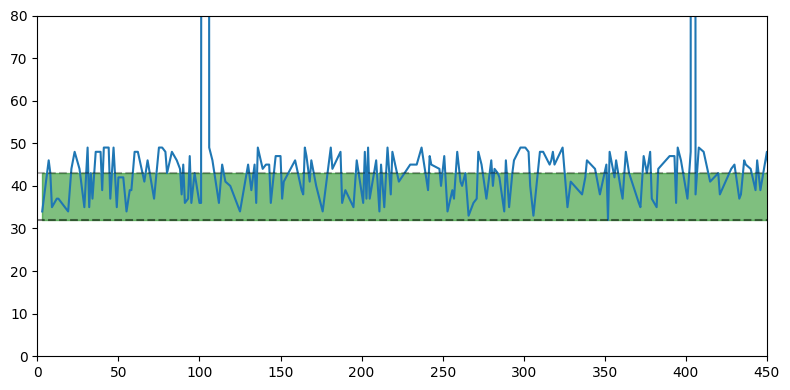

In [478]:
fig, ax = plt.subplots(figsize=(8, 4))

plt.plot(data['diff'])

plt.axhline(y=32, color='black', linestyle='--', alpha=0.5)
plt.axhline(y=43, color='black', linestyle='--', alpha=0.3)

ax.fill_between(
    x=data.index,
    y1=32,
    y2=43,
    color='green',
    alpha=0.5
)

plt.ylim(0,80)
plt.xlim(0,450)
plt.tight_layout()
plt.show()


# fill_between(x, y1, y2=0, where=None, interpolate=False, step=None, *, data=None, **kwargs)[source]#

In [ ]:
fig, ax = plt.subplots(figsize=(8, 3))

sns.boxplot(
    data=rew_diff,
    x="diff",
    ax=ax,
    color="lightgrey",
)

sns.stripplot(
    data=rew_diff,
    x="diff",
    ax=ax,
    color="blue",
    alpha=0.7,
    jitter=0,
    size=4,
)

ax.set(
    xlabel="Time before Reward state (ms)",
    title="First-Lick Time Difference on Reward Trials",
)

ax.set_xlim(20, 100)

plt.tight_layout()
plt.show()

In [489]:
pun_diff = first_licks[first_licks['state'] == "Punish"]
pun_diff['diff'].mean()

42.12844036697248

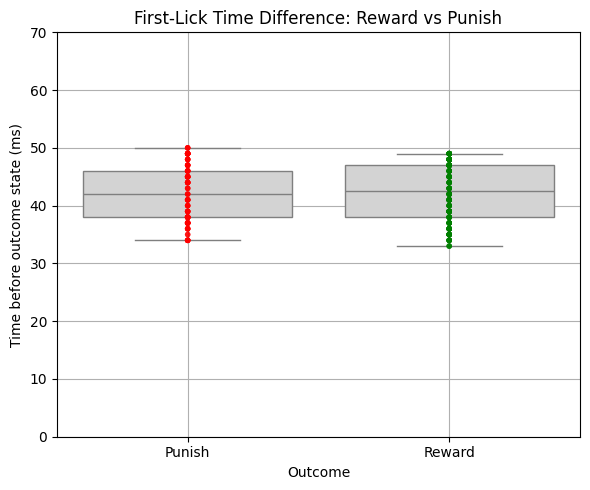

In [477]:
fig, ax = plt.subplots(figsize=(6, 5))

plot_df = first_licks[
    first_licks["state"].isin(["Punish", "Reward"])
]

sns.boxplot(
    data=plot_df,
    x="state",
    y="diff",
    order=["Punish", "Reward"],
    ax=ax,
    color="lightgrey",
)

sns.stripplot(
    data=plot_df,
    x="state",
    y="diff",
    order=["Punish", "Reward"],
    hue="state",
    palette={"Punish": "red", "Reward": "green"},
    alpha=0.7,
    jitter=0,
    size=4,
    ax=ax,
)

ax.set(
    xlabel="Outcome",
    ylabel="Time before outcome state (ms)",
    title="First-Lick Time Difference: Reward vs Punish",
)

ax.set_ylim(0, 70)
plt.grid()
plt.tight_layout()
plt.show()

In [368]:
??sns.boxplot

Signature:
sns.boxplot(
    data=None,
    *,
    x=None,
    y=None,
    hue=None,
    order=None,
    hue_order=None,
    orient=None,
    color=None,
    palette=None,
    saturation=0.75,
    fill=True,
    dodge='auto',
    width=0.8,
    gap=0,
    whis=1.5,
    linecolor='auto',
    linewidth=None,
    fliersize=None,
    hue_norm=None,
    native_scale=False,
    log_scale=None,
    formatter=None,
    legend='auto',
    ax=None,
    **kwargs,
)
Docstring:
Draw a box plot to show distributions with respect to categories.

A box plot (or box-and-whisker plot) shows the distribution of quantitative
data in a way that facilitates comparisons between variables or across
levels of a categorical variable. The box shows the quartiles of the
dataset while the whiskers extend to show the rest of the distribution,
except for points that are determined to be "outliers" using a method
that is a function of the inter-quartile range.

See the :ref:`tutorial <categorical_tutorial>` for more i

In [630]:
df_english = pd.DataFrame(
    {
        "student": ["John", "James", "Jennifer"],
        "gender": ["male", "male", "female"],
        "score": [20, 30, 30],
        "subject": "english"
    }
)
display(df_english)
df_math = pd.DataFrame(
    {
        "student": ["John", "James", "Jennifer"],
        "gender": ["male", "male", "female"],
        "score": [90, 100, 95],
        "subject": "math"
    }
)
display(df_math)

,student,gender,score,subject
0,John,male,20,english
1,James,male,30,english
2,Jennifer,female,30,english


,student,gender,score,subject
0,John,male,90,math
1,James,male,100,math
2,Jennifer,female,95,math


In [634]:
df = pd.concat(
    [df_english, df_math],
    ignore_index=True
)
df

,student,gender,score,subject
0,John,male,20,english
1,James,male,30,english
2,Jennifer,female,30,english
3,John,male,90,math
4,James,male,100,math
5,Jennifer,female,95,math


In [635]:
??pd.concat

Signature:
pd.concat(
    objs: 'Iterable[Series | DataFrame] | Mapping[HashableT, Series | DataFrame]',
    *,
    axis: 'Axis' = 0,
    join: 'str' = 'outer',
    ignore_index: 'bool' = False,
    keys: 'Iterable[Hashable] | None' = None,
    levels=None,
    names: 'list[HashableT] | None' = None,
    verify_integrity: 'bool' = False,
    sort: 'bool' = False,
    copy: 'bool | None' = None,
) -> 'DataFrame | Series'
Source:   
def concat(
    objs: Iterable[Series | DataFrame] | Mapping[HashableT, Series | DataFrame],
    *,
    axis: Axis = 0,
    join: str = "outer",
    ignore_index: bool = False,
    keys: Iterable[Hashable] | None = None,
    levels=None,
    names: list[HashableT] | None = None,
    verify_integrity: bool = False,
    sort: bool = False,
    copy: bool | None = None,
) -> DataFrame | Series:
    """
    Concatenate pandas objects along a particular axis.

    Allows optional set logic along the other axes.

    Can also add a layer of hierarchical indexing on